# Heart Disease Risk (2026): Exploratory Data Analysis and Predictive Modeling

**Course:** Statistics for Data Science (CSE303)  
**Project stage:** Complete, all 8 parts done (Dataset Description, Central Tendency and
Dispersion, Distribution and Shape, Categorical Analysis, Relationships, Data Quality,
Key Insights, Predictive Modeling)

This notebook explores the **Heart Disease Risk 2026** dataset using the statistical concepts
we learned in class: *central tendency, dispersion, distribution shape* and *EDA*, and then
builds predictive models on the same data.

We work through the project in stages:

1. Dataset Description
2. Central Tendency and Dispersion Analysis
3. Distribution and Shape (histograms, density plots, boxplots, IQR outliers)
4. Categorical Variable Analysis (frequency tables, bar/pie charts)
5. Relationships Between Variables (scatterplots, boxplots, correlation)
6. Data Quality Assessment (missing, duplicates, unusual values)
7. Key Insights (summary + variables for prediction)
8. Predictive Modeling (Linear Regression, Logistic Regression, kNN, Decision Tree,
   Random Forest, Naive Bayes)

## Setup: importing the libraries

We need a few Python libraries. `pandas` handles tables (DataFrames), `numpy` does maths,
and `matplotlib` / `seaborn` make the plots.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

print("All libraries imported.")

All libraries imported.


# Part 1: Dataset Description

## 1.1 Source of the dataset and the real-world problem

**Source:** The dataset is the **Heart Disease Risk 2026** dataset, published on **Kaggle**
(https://www.kaggle.com/datasets/srisyra02/heart-disease-risk-2026). It is a **synthetic**
(artificially generated) dataset that combines clinical measurements, lifestyle habits and
activity data to explore heart-disease risk.

**Real-world problem:** Heart disease is one of the leading causes of death worldwide. Doctors
often rely on a combination of many factors (blood pressure, cholesterol, age, lifestyle) to
judge a patient's risk. This dataset lets us practice exactly that: explore which measurements
and habits differ between patients with and without heart disease, and (later in the course)
try to **predict** whether a patient has heart disease from their measurements.

> The final column **`has_heart_disease`** is our **target variable**: `1` = the patient has
> heart disease, `0` = the patient does not. Every other column is a feature we can use to
> understand or predict that target.

## 1.2 Loading the data

First we read the CSV file into a `pandas` DataFrame and take a quick look at it.

> **Important:** `heart_disease_risk_2026.csv` must be in the same folder as this notebook.

In [2]:
df = pd.read_csv("heart_disease_risk_2026.csv")

# first 5 rows
df.head()

,patient_id,age,sex,resting_bp_systolic,resting_bp_diastolic,cholesterol_total,hdl,ldl,triglycerides,fasting_blood_sugar,...,family_history,smoker_status,alcohol_units_per_week,exercise_minutes_per_week,sleep_hours,stress_score,wearable_owner,daily_steps,diet_quality_score,has_heart_disease
0,1,44,Male,117,74,193,57,106,119,112,...,False,Never,2.9,86,5.4,19.8,True,7731,62.9,0
1,2,57,Male,139,94,185,69,110,35,114,...,False,Never,3.0,132,4.3,45.8,True,2629,74.6,1
2,3,29,Male,128,78,197,52,108,157,95,...,False,Current,3.5,128,5.1,17.7,True,9290,65.7,0
3,4,72,Male,132,86,197,59,104,143,92,...,False,Never,2.7,18,6.8,63.6,True,7373,48.5,1
4,5,62,Female,116,75,154,65,75,104,135,...,True,Former,3.3,24,8.2,58.7,False,6331,47.3,1


**Number of observations and variables:**

In [3]:
# df.shape gives (rows, columns)
n_rows, n_cols = df.shape
print("Number of observations (rows / patients): ", n_rows)
print("Number of variables     (columns / features):", n_cols)

# df.info() shows every column and its type
print()
df.info()

Number of observations (rows / patients):  9000
Number of variables     (columns / features): 27

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 9000 non-null   int64  
 1   age                        9000 non-null   int64  
 2   sex                        9000 non-null   str    
 3   resting_bp_systolic        9000 non-null   int64  
 4   resting_bp_diastolic       9000 non-null   int64  
 5   cholesterol_total          9000 non-null   int64  
 6   hdl                        9000 non-null   int64  
 7   ldl                        9000 non-null   int64  
 8   triglycerides              9000 non-null   int64  
 9   fasting_blood_sugar        9000 non-null   int64  
 10  hba1c                      9000 non-null   float64
 11  bmi                        9000 non-null   float64
 12  resting_heart_rat

In [4]:
# list every column with its number
print("All 27 variables:")
print("-" * 40)
for i, col in enumerate(df.columns, start=1):
    print(f"{i:>2}. {col}")

All 27 variables:
----------------------------------------
 1. patient_id
 2. age
 3. sex
 4. resting_bp_systolic
 5. resting_bp_diastolic
 6. cholesterol_total
 7. hdl
 8. ldl
 9. triglycerides
10. fasting_blood_sugar
11. hba1c
12. bmi
13. resting_heart_rate
14. max_heart_rate_achieved
15. chest_pain_type
16. exercise_induced_angina
17. st_depression
18. family_history
19. smoker_status
20. alcohol_units_per_week
21. exercise_minutes_per_week
22. sleep_hours
23. stress_score
24. wearable_owner
25. daily_steps
26. diet_quality_score
27. has_heart_disease


## 1.3 Description of each feature

The table below describes **all 27 features**: the Python data type, what the feature means,
and how we classify it (numerical vs categorical). Remember:

- **Numerical (continuous):** can take any value in a range, e.g. blood pressure in mmHg.
- **Numerical (discrete):** counted values, e.g. number of steps.
- **Categorical (nominal):** categories with no natural order, e.g. type of chest pain.
- **Categorical (ordinal):** categories that have a natural order.
- **Categorical (binary):** only two possible values, e.g. True/False, Male/Female.

In [5]:
# each feature maps to [data type, description, classification]
feature_info = {
    "patient_id":               ["int64",   "Unique ID number of each patient",                            "Categorical (nominal) - identifier"],
    "age":                      ["int64",   "Age of the patient in years",                                 "Numerical (discrete)"],
    "sex":                      ["str",     "Biological sex of the patient (Male / Female)",               "Categorical (binary)"],
    "resting_bp_systolic":      ["int64",   "Systolic blood pressure at rest (mm Hg)",                      "Numerical (continuous)"],
    "resting_bp_diastolic":     ["int64",   "Diastolic blood pressure at rest (mm Hg)",                     "Numerical (continuous)"],
    "cholesterol_total":        ["int64",   "Total cholesterol level (mg/dL)",                              "Numerical (continuous)"],
    "hdl":                      ["int64",   "HDL - 'good' cholesterol level (mg/dL)",                       "Numerical (continuous)"],
    "ldl":                      ["int64",   "LDL - 'bad' cholesterol level (mg/dL)",                        "Numerical (continuous)"],
    "triglycerides":            ["int64",   "Triglyceride level (mg/dL)",                                   "Numerical (continuous)"],
    "fasting_blood_sugar":      ["int64",   "Fasting blood sugar level (mg/dL)",                            "Numerical (continuous)"],
    "hba1c":                    ["float64", "HbA1c - average blood sugar over the last ~3 months (%)",      "Numerical (continuous)"],
    "bmi":                      ["float64", "Body Mass Index (kg/m^2)",                                     "Numerical (continuous)"],
    "resting_heart_rate":       ["int64",   "Resting heart rate (beats per minute)",                        "Numerical (continuous)"],
    "max_heart_rate_achieved":  ["int64",   "Highest heart rate reached during exercise (bpm)",             "Numerical (continuous)"],
    "chest_pain_type":          ["str",     "Type of chest pain (Asymptomatic / Non-Anginal Pain / Atypical Angina / Typical Angina)", "Categorical (nominal)"],
    "exercise_induced_angina":  ["bool",    "Whether exercise caused chest pain (True/False)",              "Categorical (binary)"],
    "st_depression":            ["float64", "ST-segment depression measured on an ECG (mm)",                "Numerical (continuous)"],
    "family_history":           ["bool",    "Whether a close family member has heart disease",              "Categorical (binary)"],
    "smoker_status":            ["str",     "Smoking status (Never / Former / Current)",                    "Categorical (nominal)"],
    "alcohol_units_per_week":   ["float64", "Alcohol consumed per week (units)",                            "Numerical (continuous)"],
    "exercise_minutes_per_week":["int64",   "Minutes of exercise per week",                                 "Numerical (continuous)"],
    "sleep_hours":              ["float64", "Average hours of sleep per night",                             "Numerical (continuous)"],
    "stress_score":             ["float64", "Self-reported stress level (0-100)",                           "Numerical (continuous)"],
    "wearable_owner":           ["bool",    "Whether the patient owns a wearable device",                   "Categorical (binary)"],
    "daily_steps":              ["int64",   "Average daily step count",                                     "Numerical (discrete)"],
    "diet_quality_score":       ["float64", "Diet quality score (0-100)",                                   "Numerical (continuous)"],
    "has_heart_disease":        ["int64",   "TARGET: 1 = has heart disease, 0 = does not",                  "Categorical (binary) - target"],
}

# turn the dictionary into a DataFrame (rows = features)
feature_table = pd.DataFrame(
    feature_info,
    index=["Python data type", "Description / meaning", "Classification"],
).T

feature_table

,Python data type,Description / meaning,Classification
patient_id,int64,Unique ID number of each patient,Categorical (nominal) - identifier
age,int64,Age of the patient in years,Numerical (discrete)
sex,str,Biological sex of the patient (Male / Female),Categorical (binary)
resting_bp_systolic,int64,Systolic blood pressure at rest (mm Hg),Numerical (continuous)
resting_bp_diastolic,int64,Diastolic blood pressure at rest (mm Hg),Numerical (continuous)
cholesterol_total,int64,Total cholesterol level (mg/dL),Numerical (continuous)
hdl,int64,HDL - 'good' cholesterol level (mg/dL),Numerical (continuous)
ldl,int64,LDL - 'bad' cholesterol level (mg/dL),Numerical (continuous)
triglycerides,int64,Triglyceride level (mg/dL),Numerical (continuous)
fasting_blood_sugar,int64,Fasting blood sugar level (mg/dL),Numerical (continuous)


In [6]:
# split the columns into numerical and categorical
numerical_features = [
    "age", "resting_bp_systolic", "resting_bp_diastolic",
    "cholesterol_total", "hdl", "ldl", "triglycerides",
    "fasting_blood_sugar", "hba1c", "bmi",
    "resting_heart_rate", "max_heart_rate_achieved", "st_depression",
    "alcohol_units_per_week", "exercise_minutes_per_week", "sleep_hours",
    "stress_score", "daily_steps", "diet_quality_score",
]

categorical_features = [
    "sex", "chest_pain_type", "exercise_induced_angina",
    "family_history", "smoker_status", "wearable_owner", "has_heart_disease",
]

print("Number of numerical features  :", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print()
print("Numerical features  :", numerical_features)
print("Categorical features:", categorical_features)

Number of numerical features  : 19
Number of categorical features: 7

Numerical features  : ['age', 'resting_bp_systolic', 'resting_bp_diastolic', 'cholesterol_total', 'hdl', 'ldl', 'triglycerides', 'fasting_blood_sugar', 'hba1c', 'bmi', 'resting_heart_rate', 'max_heart_rate_achieved', 'st_depression', 'alcohol_units_per_week', 'exercise_minutes_per_week', 'sleep_hours', 'stress_score', 'daily_steps', 'diet_quality_score']
Categorical features: ['sex', 'chest_pain_type', 'exercise_induced_angina', 'family_history', 'smoker_status', 'wearable_owner', 'has_heart_disease']


# Part 2: Central Tendency and Dispersion Analysis

## 2.1 What we are computing

For every **numerical** feature we compute:

| Measure | What it tells us |
|---|---|
| **Mean** | The average value. A 'balancing point' of the data. |
| **Median** | The middle value when the data is sorted. Not affected by extreme values. |
| **Mode** | The most frequent value. (Least useful for continuous data.) |
| **Variance** | Average squared distance of values from the mean. |
| **Standard deviation (Std)** | Square root of the variance. Average distance from the mean, in the same units as the data. |
| **Q1, Q3** | 25th and 75th percentiles. |
| **IQR** | Q3 - Q1. The spread of the middle 50% of the data. |

**Reading tip:** if **mean ≈ median**, the distribution is roughly *symmetric*.
If **mean > median**, it is *right-skewed* (a few unusually large values pull the mean up).
If **mean < median**, it is *left-skewed*.

We exclude `patient_id` (just an ID), `has_heart_disease` (a 0/1 target) and the
categorical/bool columns (they get their own treatment in Part 4).

In [7]:
# numerical columns we analyse (same list as in Part 1)
numerical_cols = numerical_features

# one row of statistics per feature
stats_rows = []

for col in numerical_cols:
    mean = df[col].mean()       # average
    median = df[col].median()   # middle value
    modes = df[col].mode()      # most frequent value(s)
    mode_str = ", ".join(str(m) for m in modes)
    variance = df[col].var()    # average squared distance from the mean
    std = df[col].std()         # typical distance from the mean
    q1 = df[col].quantile(0.25) # 25th percentile
    q3 = df[col].quantile(0.75) # 75th percentile
    iqr = q3 - q1               # interquartile range

    stats_rows.append([col, mean, median, mode_str, variance, std, q1, q3, iqr])

summary_stats = pd.DataFrame(
    stats_rows,
    columns=["Feature", "Mean", "Median", "Mode(s)", "Variance",
             "Std Dev", "Q1 (25%)", "Q3 (75%)", "IQR"],
)

# round to 2 decimals for a cleaner table
summary_stats = summary_stats.round(2)

summary_stats

,Feature,Mean,Median,Mode(s),Variance,Std Dev,Q1 (25%),Q3 (75%),IQR
0,age,53.98,54.0,57,169.21,13.01,45.0,63.00,18.00
1,resting_bp_systolic,127.85,128.0,127,189.54,13.77,119.0,137.00,18.00
2,resting_bp_diastolic,80.79,81.0,80,119.68,10.94,74.0,88.00,14.00
3,cholesterol_total,188.75,189.0,187,1041.46,32.27,167.0,211.00,44.00
4,hdl,55.22,55.0,58,153.62,12.39,47.0,64.00,17.00
5,ldl,103.28,103.0,99,747.60,27.34,85.0,122.00,37.00
6,triglycerides,152.04,151.0,35,2646.94,51.45,117.0,186.00,69.00
7,fasting_blood_sugar,119.47,119.0,119,518.84,22.78,104.0,135.00,31.00
8,hba1c,5.79,5.8,"5.8, 5.9",0.48,0.69,5.3,6.30,1.00
9,bmi,25.26,25.3,25.8,19.11,4.37,22.3,28.20,5.90


## 2.2 Interpreting the results

### What stands out

**Age:** mean ≈ 54 and median ≈ 54, with IQR 45–63. Mean and median are almost identical,
so age is fairly **symmetric** and covers a realistic adult range (standard deviation ≈ 13 years).

**Blood pressure:** systolic mean ≈ 128 mm Hg and diastolic ≈ 81 mm Hg. This sits at the
*borderline* between normal and elevated blood pressure, which is medically meaningful.

**Cholesterol (total):** mean ≈ 189 mg/dL with a moderate spread (std ≈ 32, IQR 44). Values
above 200 mg/dL are considered high, so part of the sample is at risk.

**BMI:** mean ≈ 25.3. A BMI of 25–30 is classed as *overweight*, so on average the sample is
just over the healthy-weight boundary.

**Signs of right-skewness (mean > median):**
- `st_depression` (mean 1.01 vs median 0.70): most patients have small values but a few have large ones.
- `alcohol_units_per_week` (mean 5.71 vs median 4.20): the majority drink little, a few drink a lot.
- `daily_steps` (mean 6164 vs median 6178, std ≈ 2171): the **most variable** feature (largest IQR ≈ 2975). Its mode is 500, meaning many patients have very low step counts.

**Signs of near-symmetry (mean ≈ median):**
- `stress_score` (48.0 vs 48.1) and `sleep_hours` (7.0 vs 7.0) are almost perfectly balanced.

**Interesting modes (spikes at low values):**
- `exercise_minutes_per_week` mode = 0 → many patients record **no exercise** at all.
- `triglycerides` mode = 35 → a big group sits at a very low value while the mean stays at 152.

### Cautions
- For continuous variables the **mode is rarely informative** (each value may appear only once or twice), so we report it for completeness.
- Comparing mean vs median only *hints* at the shape. We **confirm the shape** in Part 3 using histograms, density plots and boxplots, and count the outliers with the IQR rule.
- `has_heart_disease` has 6273 zeros vs 2727 ones, so the target is **imbalanced**, which is useful to remember when we build a predictive model later.

### So far
The sample looks like a realistic middle-aged population with blood pressure, cholesterol and
BMI sitting close to clinical risk boundaries, and several lifestyle features (steps, exercise,
alcohol) that are right-skewed. These will be interesting predictors to look at in later parts.

# Part 3: Distribution and Shape

In Part 2 we summarised each numerical feature with single numbers. Now we look at the
**shape** of each distribution using three plots side by side (1 row, 3 columns):

1. **Histogram:** the bars show how many patients fall in each value range.
2. **Density plot:** the same histogram bars plus a smooth **red density curve** over them.
   The curve makes the shape easier to compare across features.
3. **Boxplot:** shows the median (line in the box), the box (middle 50%) and the outliers.

On the histogram and density plot we draw two vertical **mean / median lines**,
so we can immediately see on which side each one falls.

### How we decide the shape
We use the **skewness coefficient** (a number that measures asymmetry):

| Skewness value | Shape |
|---|---|
| between -0.5 and +0.5 | **Symmetric** (mean ≈ median) |
| more than +0.5 | **Right-skewed** (mean > median, long right tail) |
| less than -0.5 | **Left-skewed** (mean < median, long left tail) |

If the mean and median are very close to each other, we also call the distribution **symmetric**.

### How we find outliers (the IQR rule)
A value is an **outlier** if it lies outside the fence:

```
lower fence = Q1 - 1.5 * IQR      upper fence = Q3 + 1.5 * IQR
```

where IQR = Q3 - Q1. These are the same dots you see outside the boxplot whiskers.

In [8]:
# helper functions used for every numerical feature
sns.set_style("whitegrid")

def plot_distribution(col):
    # draws the 1 x 3 plot for one column and returns the numbers we need
    d = df[col]

    # skewness and shape
    skew_val = d.skew()
    if abs(skew_val) < 0.5:
        shape = "Symmetric"
    elif skew_val > 0:
        shape = "Right-Skewed"
    else:
        shape = "Left-Skewed"

    # 1 row, 3 columns
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"{col} - Distribution Plots", fontsize=14)

    # histogram
    axes[0].hist(d, bins=35, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0].axvline(d.mean(),   color='crimson',   linestyle='--', linewidth=2,
                    label=f"Mean: {d.mean():.2f}")
    axes[0].axvline(d.median(), color='darkgreen', linestyle='--', linewidth=2,
                    label=f"Median: {d.median():.2f}")
    axes[0].annotate(f"Skewness: {skew_val:.2f} ({shape})",
                     xy=(0.02, 0.97), xycoords="axes fraction",
                     fontsize=9, ha="left", va="top",
                     bbox=dict(boxstyle="round,pad=0.3", facecolor="wheat", alpha=0.8))
    axes[0].set_title("Histogram")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")
    axes[0].legend(fontsize=8)

    # density plot
    axes[1].hist(d, bins=35, density=True, color='steelblue', edgecolor='black',
                 alpha=0.5, label="Histogram (bars)")
    d.plot(kind='density', ax=axes[1], color='red', linewidth=2, label="Density curve")
    axes[1].axvline(d.mean(),   color='crimson',   linestyle='--', linewidth=2,
                    label=f"Mean: {d.mean():.2f}")
    axes[1].axvline(d.median(), color='darkgreen', linestyle='--', linewidth=2,
                    label=f"Median: {d.median():.2f}")
    axes[1].set_title("Density Plot")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Density")
    axes[1].legend(fontsize=8)

    # boxplot
    axes[2].boxplot(d, orientation='horizontal', patch_artist=True,
                    boxprops={'facecolor': 'lightblue'})
    axes[2].set_title("Boxplot (horizontal)")
    axes[2].set_xlabel(col)

    plt.tight_layout()
    fig.subplots_adjust(top=0.85)
    plt.show()

    # numbers for the interpretation
    q1, q3 = d.quantile(0.25), d.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = d[(d < lower) | (d > upper)]

    return {'mean': d.mean(), 'median': d.median(), 'skew': skew_val, 'shape': shape,
            'q1': q1, 'q3': q3, 'iqr': iqr, 'lower': lower, 'upper': upper,
            'n_out': len(outliers), 'pct_out': len(outliers) / len(d) * 100}

def print_interpretation(col, info, comment):
    # prints the interpretation block for one numerical feature
    diff = abs(info['mean'] - info['median'])
    if info['shape'] == "Symmetric":
        mean_median_note = f"difference = {diff:.2f} (low -> symmetric)"
    else:
        side = "mean > median" if info['mean'] > info['median'] else "mean < median"
        mean_median_note = f"difference = {diff:.2f} ({side} -> {info['shape']})"
    print(f"Interpretation: {col}")
    print(f"  Shape: {info['shape']} (Skewness = {info['skew']:.3f})")
    print(f"  Mean = {info['mean']:.2f} | Median = {info['median']:.2f} | {mean_median_note}")
    print(f"  IQR = {info['iqr']:.2f} (Q1 = {info['q1']:.2f}, Q3 = {info['q3']:.2f})")
    print(f"  Outlier bounds: below {info['lower']:.2f} or above {info['upper']:.2f}")
    print(f"  Outliers: {info['n_out']} patients ({info['pct_out']:.1f}%)")
    print(f"  Comment: {comment}")
    print()

In [9]:
# A dictionary of the interpretation comments for every numerical feature
comments = {
    'age': 'Age is nicely symmetric (skew ~ -0.02, mean ~ median ~ 54) and the IQR rule finds NO outliers. The sample covers a wide adult age range with no extreme ages.',
    'resting_bp_systolic': "Nearly symmetric, centred around 128 mm Hg - right at the 'elevated' blood pressure boundary. The 66 high-side outliers (above 164) are patients with clear hypertension; these are clinically real, not data errors.",
    'resting_bp_diastolic': 'Almost perfectly symmetric (skew ~ 0.01) with a tight IQR of 14. The 75 outliers lie mainly on the high side (above 109), pointing to patients with elevated diastolic pressure.',
    'cholesterol_total': 'Symmetric around 189 mg/dL - borderline high cholesterol (above 200 is considered high). The 50 high-side outliers (above 277) represent severe hypercholesterolaemia cases.',
    'hdl': "HDL is symmetric around 55 mg/dL. Outliers appear on both sides: very low HDL (below 21.5, poor) and very high HDL (above 89.5, excellent). HDL is the 'good' cholesterol, so higher is better.",
    'ldl': "Symmetric around 103 mg/dL. The 34 outliers sit on the high side (above 178) - high LDL ('bad' cholesterol) is a known heart-disease risk factor.",
    'triglycerides': 'Largely symmetric (skew ~ 0.13) but with a big spike at very low values (mode = 35). The 42 high-side outliers (above 290) are patients with very high triglycerides.',
    'fasting_blood_sugar': 'Symmetric around 119 mg/dL (normal fasting sugar is below 100, so the sample leans slightly high). The 32 high-side outliers (above 181) are at diabetic levels.',
    'hba1c': 'Very tight and symmetric (IQR only 1.0). Just 10 high-side outliers (above 7.8) - HbA1c above 6.5 indicates diabetes, so these few patients are likely diabetic.',
    'bmi': "Roughly symmetric (skew ~ 0.09) with mean 25.3, just over the 'overweight' boundary. The 39 outliers are mostly on the high side (above 37) - obese patients.",
    'resting_heart_rate': 'Bell-shaped and symmetric around 81 bpm. The 42 outliers appear on both sides: very low rates (bradycardia, below 57) and very high rates (tachycardia, above 105).',
    'max_heart_rate_achieved': 'Near-symmetric with a very slight left lean (skew ~ -0.19). Only 17 low-side outliers (below 105) - patients whose exercise capacity is limited, possibly by heart disease.',
    'st_depression': 'STRONGLY RIGHT-SKEWED (skew ~ 2.04): most patients have small values (median 0.70) but a few have very large ones. 485 outliers (5.4%) - the most of any feature. High ST depression is a classic ECG sign of heart disease, so these outliers are clinically meaningful.',
    'alcohol_units_per_week': 'STRONGLY RIGHT-SKEWED (skew ~ 2.03): most people drink little (median 4.2 units/week) but a minority drink a lot. 431 outliers (4.8%) lie above 16 units/week.',
    'exercise_minutes_per_week': 'Mean ~ median (both ~139), so the middle of the data is symmetric - but the mode is 0, meaning many patients do no exercise at all. The 27 high-side outliers are very active people (above 314 minutes/week).',
    'sleep_hours': 'Symmetric around 7 hours (the recommended sleep duration). The 86 outliers sit at both extremes: very little sleep (below 4.2h) and very long sleep (above 9.8h).',
    'stress_score': 'Symmetric around 48 (the middle of the 0-100 scale) with skew ~ -0.01. Only 71 outliers (0.8%), split on both sides.',
    'daily_steps': 'Symmetric around ~6164 steps with the widest spread of all features (std ~ 2171). The mode of 500 shows many patients are very sedentary, and the 32 low-side outliers have near-zero step counts.',
    'diet_quality_score': 'Perfectly symmetric (skew ~ 0.00) around 59.5 (middle of the 0-100 scale). The 69 outliers on both sides represent the extremes of diet quality.',
}

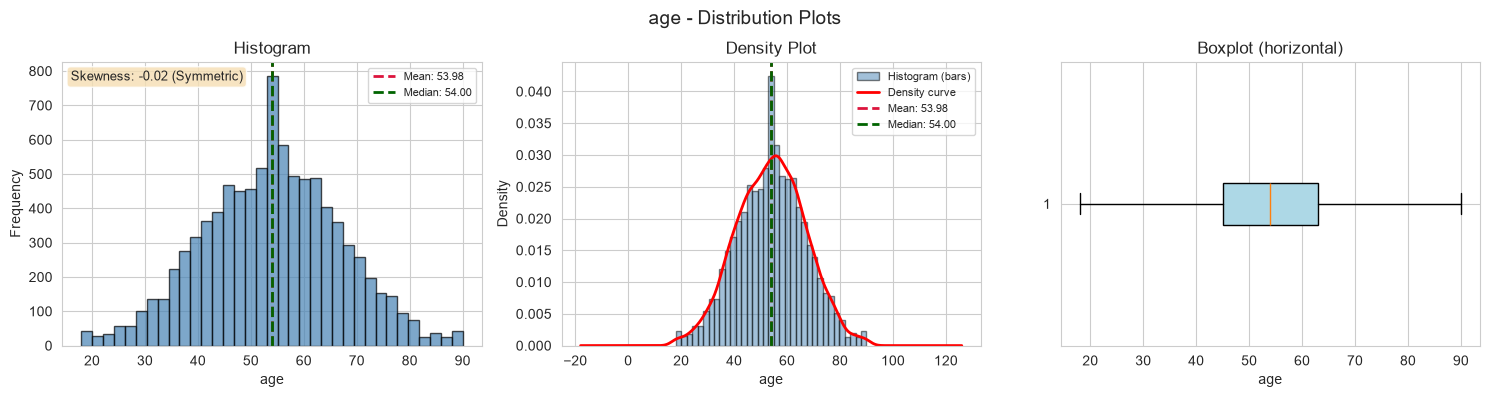

Interpretation: age
  Shape: Symmetric (Skewness = -0.022)
  Mean = 53.98 | Median = 54.00 | difference = 0.02 (low -> symmetric)
  IQR = 18.00 (Q1 = 45.00, Q3 = 63.00)
  Outlier bounds: below 18.00 or above 90.00
  Outliers: 0 patients (0.0%)
  Comment: Age is nicely symmetric (skew ~ -0.02, mean ~ median ~ 54) and the IQR rule finds NO outliers. The sample covers a wide adult age range with no extreme ages.



In [10]:
# ===== AGE =====
info = plot_distribution("age")
print_interpretation("age", info, comments["age"])

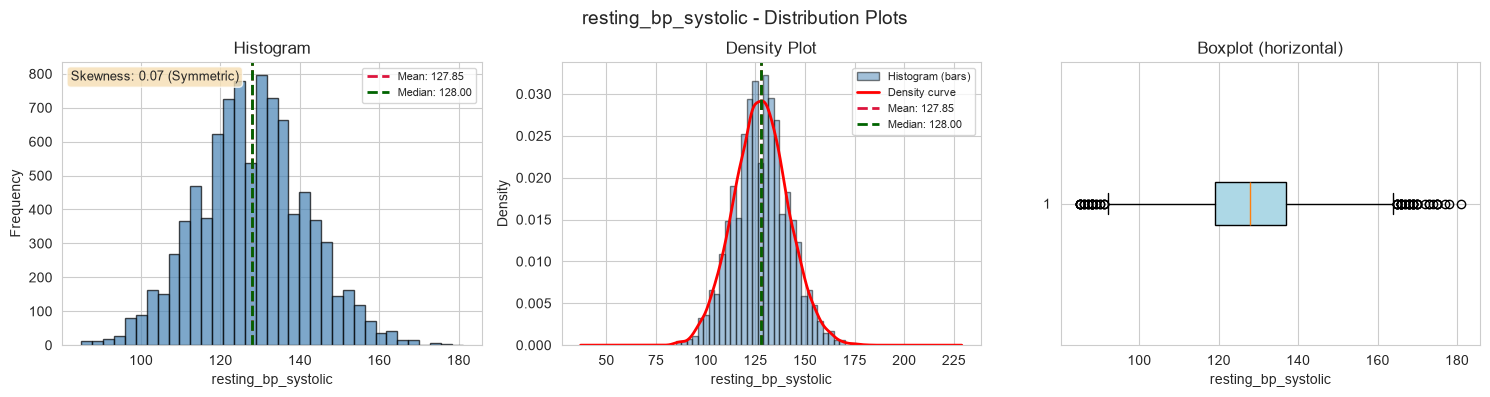

Interpretation: resting_bp_systolic
  Shape: Symmetric (Skewness = 0.068)
  Mean = 127.85 | Median = 128.00 | difference = 0.15 (low -> symmetric)
  IQR = 18.00 (Q1 = 119.00, Q3 = 137.00)
  Outlier bounds: below 92.00 or above 164.00
  Outliers: 66 patients (0.7%)
  Comment: Nearly symmetric, centred around 128 mm Hg - right at the 'elevated' blood pressure boundary. The 66 high-side outliers (above 164) are patients with clear hypertension; these are clinically real, not data errors.



In [11]:
# ===== RESTING_BP_SYSTOLIC =====
info = plot_distribution("resting_bp_systolic")
print_interpretation("resting_bp_systolic", info, comments["resting_bp_systolic"])

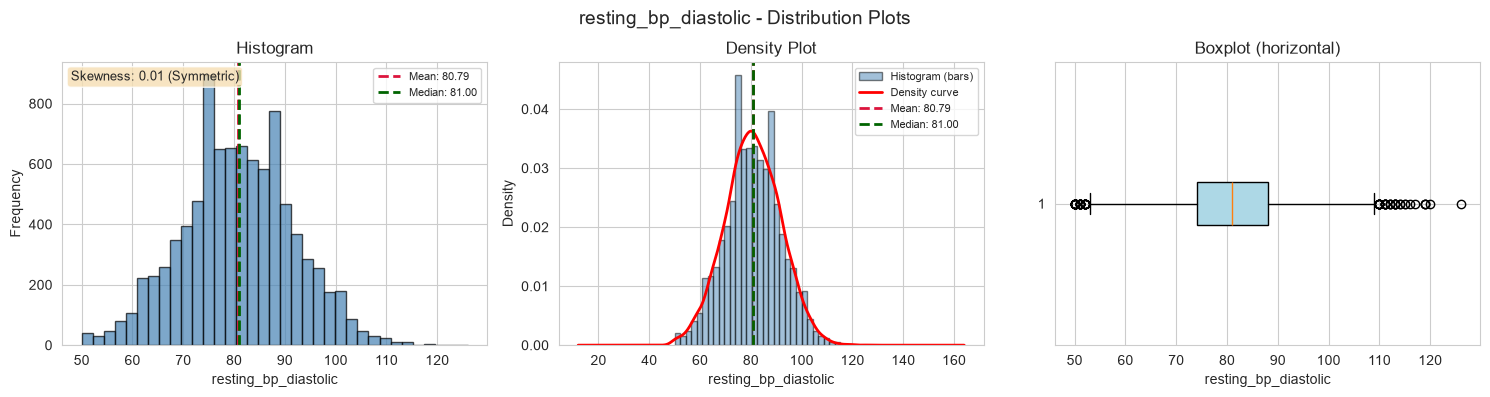

Interpretation: resting_bp_diastolic
  Shape: Symmetric (Skewness = 0.009)
  Mean = 80.79 | Median = 81.00 | difference = 0.21 (low -> symmetric)
  IQR = 14.00 (Q1 = 74.00, Q3 = 88.00)
  Outlier bounds: below 53.00 or above 109.00
  Outliers: 75 patients (0.8%)
  Comment: Almost perfectly symmetric (skew ~ 0.01) with a tight IQR of 14. The 75 outliers lie mainly on the high side (above 109), pointing to patients with elevated diastolic pressure.



In [12]:
# ===== RESTING_BP_DIASTOLIC =====
info = plot_distribution("resting_bp_diastolic")
print_interpretation("resting_bp_diastolic", info, comments["resting_bp_diastolic"])

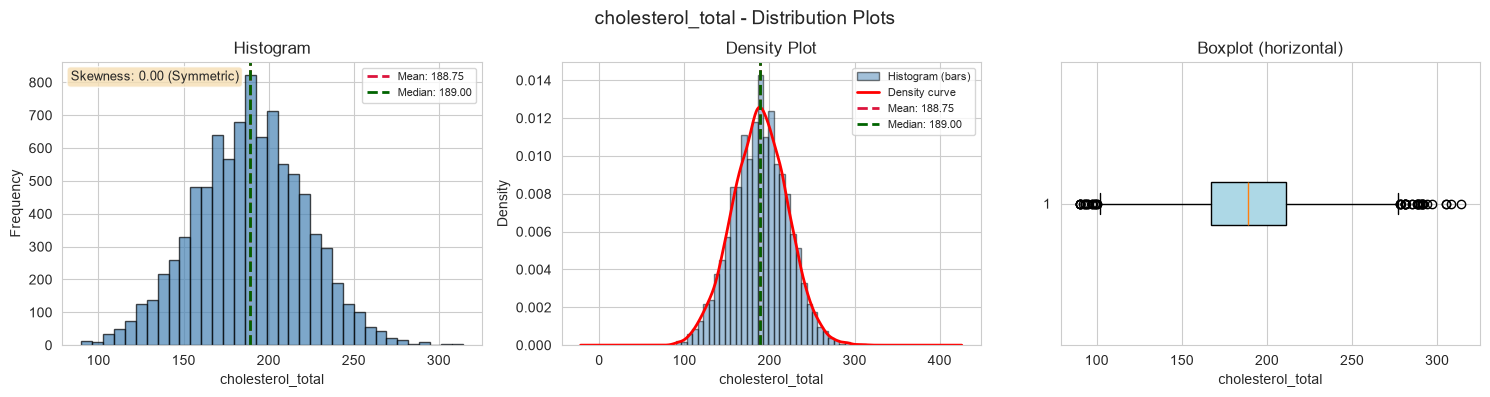

Interpretation: cholesterol_total
  Shape: Symmetric (Skewness = 0.004)
  Mean = 188.75 | Median = 189.00 | difference = 0.25 (low -> symmetric)
  IQR = 44.00 (Q1 = 167.00, Q3 = 211.00)
  Outlier bounds: below 101.00 or above 277.00
  Outliers: 50 patients (0.6%)
  Comment: Symmetric around 189 mg/dL - borderline high cholesterol (above 200 is considered high). The 50 high-side outliers (above 277) represent severe hypercholesterolaemia cases.



In [13]:
# ===== CHOLESTEROL_TOTAL =====
info = plot_distribution("cholesterol_total")
print_interpretation("cholesterol_total", info, comments["cholesterol_total"])

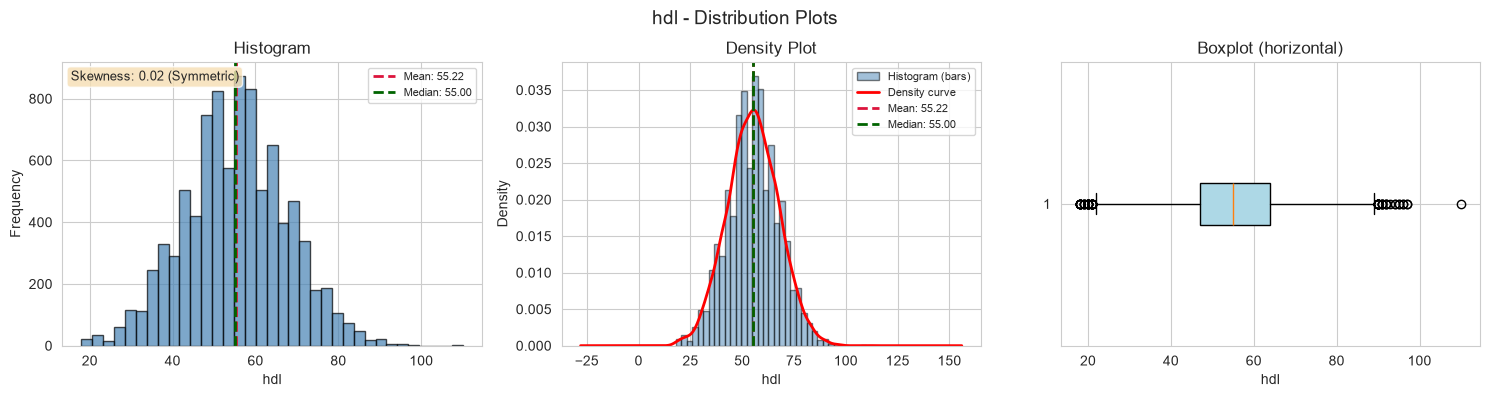

Interpretation: hdl
  Shape: Symmetric (Skewness = 0.020)
  Mean = 55.22 | Median = 55.00 | difference = 0.22 (low -> symmetric)
  IQR = 17.00 (Q1 = 47.00, Q3 = 64.00)
  Outlier bounds: below 21.50 or above 89.50
  Outliers: 63 patients (0.7%)
  Comment: HDL is symmetric around 55 mg/dL. Outliers appear on both sides: very low HDL (below 21.5, poor) and very high HDL (above 89.5, excellent). HDL is the 'good' cholesterol, so higher is better.



In [14]:
# ===== HDL =====
info = plot_distribution("hdl")
print_interpretation("hdl", info, comments["hdl"])

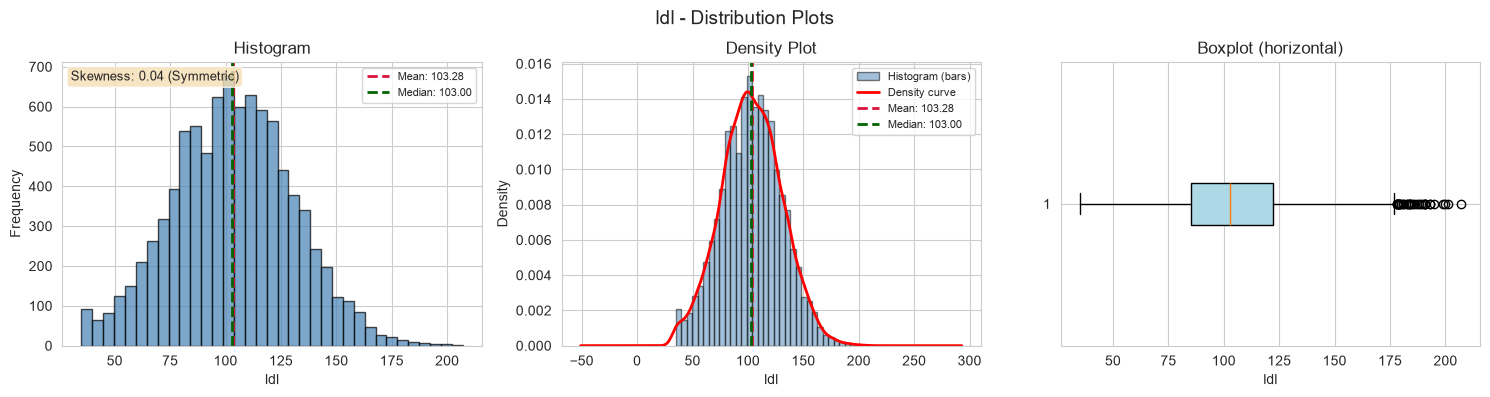

Interpretation: ldl
  Shape: Symmetric (Skewness = 0.045)
  Mean = 103.28 | Median = 103.00 | difference = 0.28 (low -> symmetric)
  IQR = 37.00 (Q1 = 85.00, Q3 = 122.00)
  Outlier bounds: below 29.50 or above 177.50
  Outliers: 34 patients (0.4%)
  Comment: Symmetric around 103 mg/dL. The 34 outliers sit on the high side (above 178) - high LDL ('bad' cholesterol) is a known heart-disease risk factor.



In [15]:
# ===== LDL =====
info = plot_distribution("ldl")
print_interpretation("ldl", info, comments["ldl"])

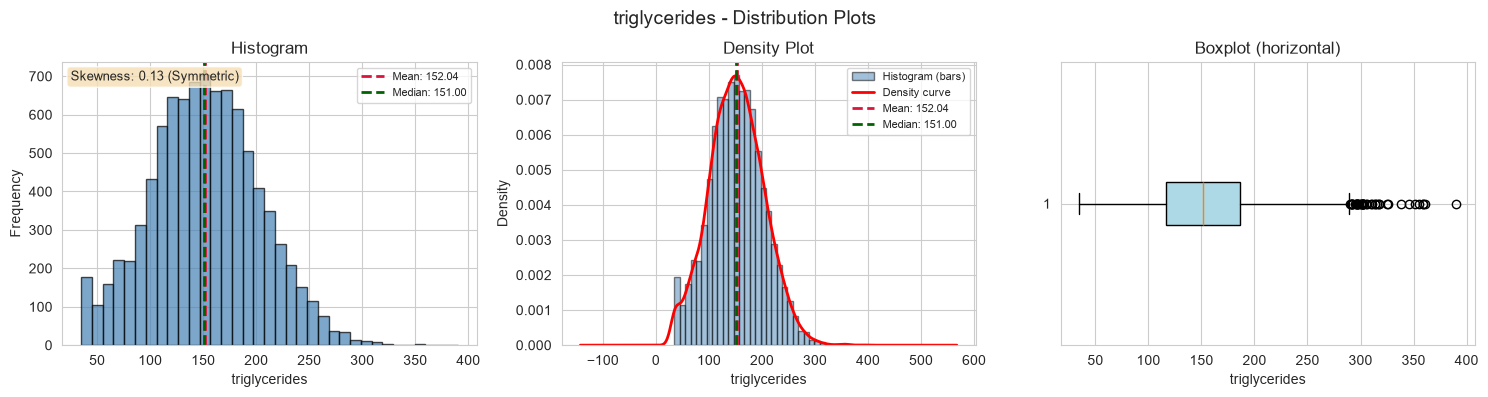

Interpretation: triglycerides
  Shape: Symmetric (Skewness = 0.126)
  Mean = 152.04 | Median = 151.00 | difference = 1.04 (low -> symmetric)
  IQR = 69.00 (Q1 = 117.00, Q3 = 186.00)
  Outlier bounds: below 13.50 or above 289.50
  Outliers: 42 patients (0.5%)
  Comment: Largely symmetric (skew ~ 0.13) but with a big spike at very low values (mode = 35). The 42 high-side outliers (above 290) are patients with very high triglycerides.



In [16]:
# ===== TRIGLYCERIDES =====
info = plot_distribution("triglycerides")
print_interpretation("triglycerides", info, comments["triglycerides"])

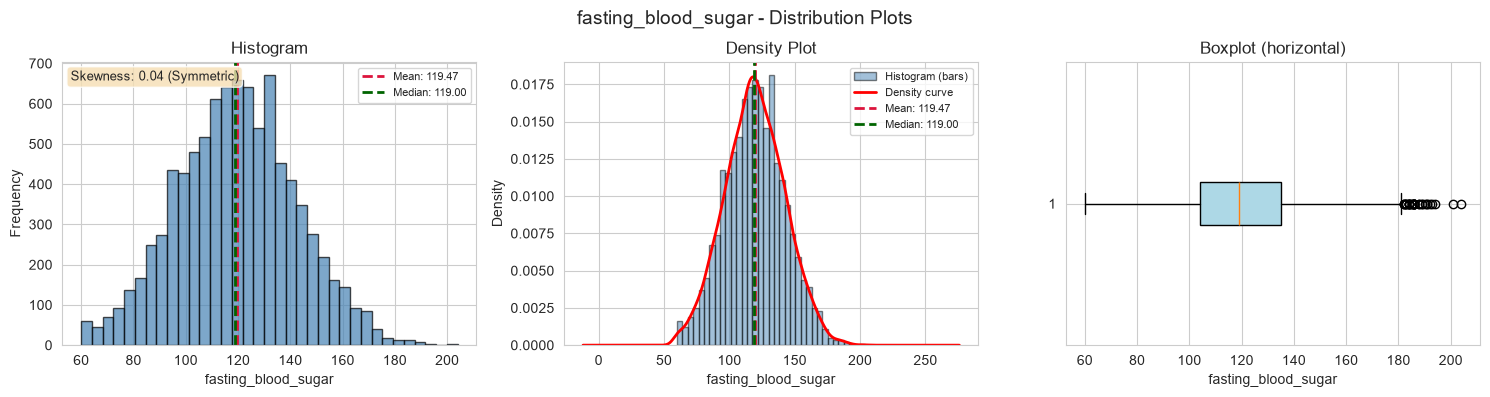

Interpretation: fasting_blood_sugar
  Shape: Symmetric (Skewness = 0.041)
  Mean = 119.47 | Median = 119.00 | difference = 0.47 (low -> symmetric)
  IQR = 31.00 (Q1 = 104.00, Q3 = 135.00)
  Outlier bounds: below 57.50 or above 181.50
  Outliers: 32 patients (0.4%)
  Comment: Symmetric around 119 mg/dL (normal fasting sugar is below 100, so the sample leans slightly high). The 32 high-side outliers (above 181) are at diabetic levels.



In [17]:
# ===== FASTING_BLOOD_SUGAR =====
info = plot_distribution("fasting_blood_sugar")
print_interpretation("fasting_blood_sugar", info, comments["fasting_blood_sugar"])

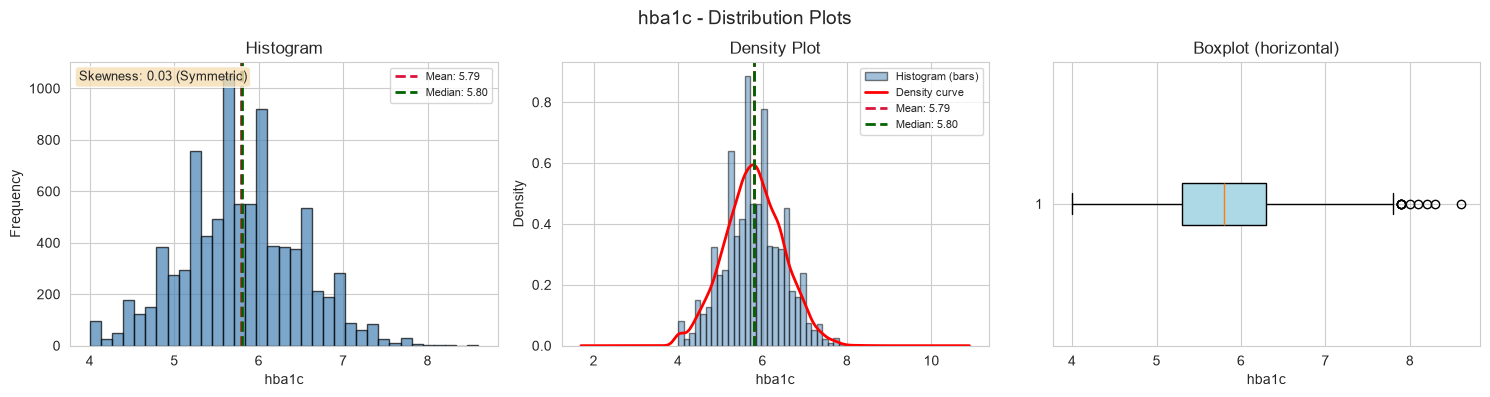

Interpretation: hba1c
  Shape: Symmetric (Skewness = 0.029)
  Mean = 5.79 | Median = 5.80 | difference = 0.01 (low -> symmetric)
  IQR = 1.00 (Q1 = 5.30, Q3 = 6.30)
  Outlier bounds: below 3.80 or above 7.80
  Outliers: 10 patients (0.1%)
  Comment: Very tight and symmetric (IQR only 1.0). Just 10 high-side outliers (above 7.8) - HbA1c above 6.5 indicates diabetes, so these few patients are likely diabetic.



In [18]:
# ===== HBA1C =====
info = plot_distribution("hba1c")
print_interpretation("hba1c", info, comments["hba1c"])

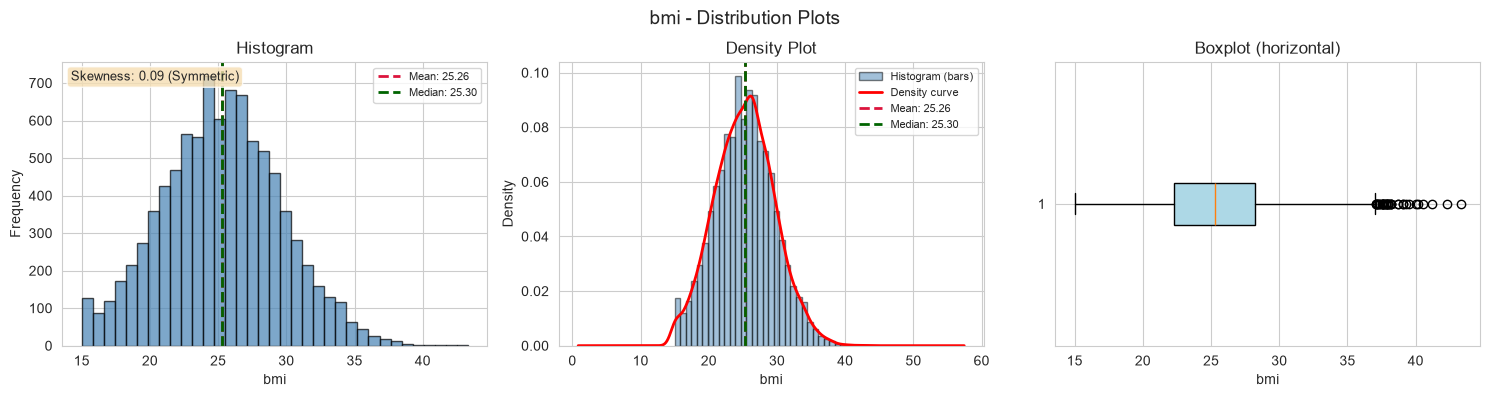

Interpretation: bmi
  Shape: Symmetric (Skewness = 0.092)
  Mean = 25.26 | Median = 25.30 | difference = 0.04 (low -> symmetric)
  IQR = 5.90 (Q1 = 22.30, Q3 = 28.20)
  Outlier bounds: below 13.45 or above 37.05
  Outliers: 39 patients (0.4%)
  Comment: Roughly symmetric (skew ~ 0.09) with mean 25.3, just over the 'overweight' boundary. The 39 outliers are mostly on the high side (above 37) - obese patients.



In [19]:
# ===== BMI =====
info = plot_distribution("bmi")
print_interpretation("bmi", info, comments["bmi"])

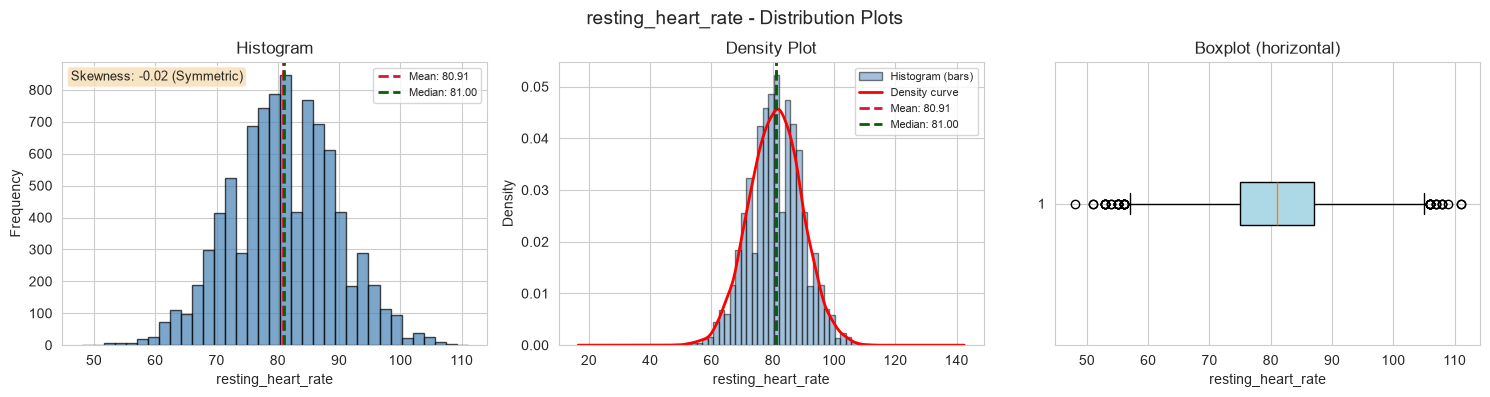

Interpretation: resting_heart_rate
  Shape: Symmetric (Skewness = -0.019)
  Mean = 80.91 | Median = 81.00 | difference = 0.09 (low -> symmetric)
  IQR = 12.00 (Q1 = 75.00, Q3 = 87.00)
  Outlier bounds: below 57.00 or above 105.00
  Outliers: 42 patients (0.5%)
  Comment: Bell-shaped and symmetric around 81 bpm. The 42 outliers appear on both sides: very low rates (bradycardia, below 57) and very high rates (tachycardia, above 105).



In [20]:
# ===== RESTING_HEART_RATE =====
info = plot_distribution("resting_heart_rate")
print_interpretation("resting_heart_rate", info, comments["resting_heart_rate"])

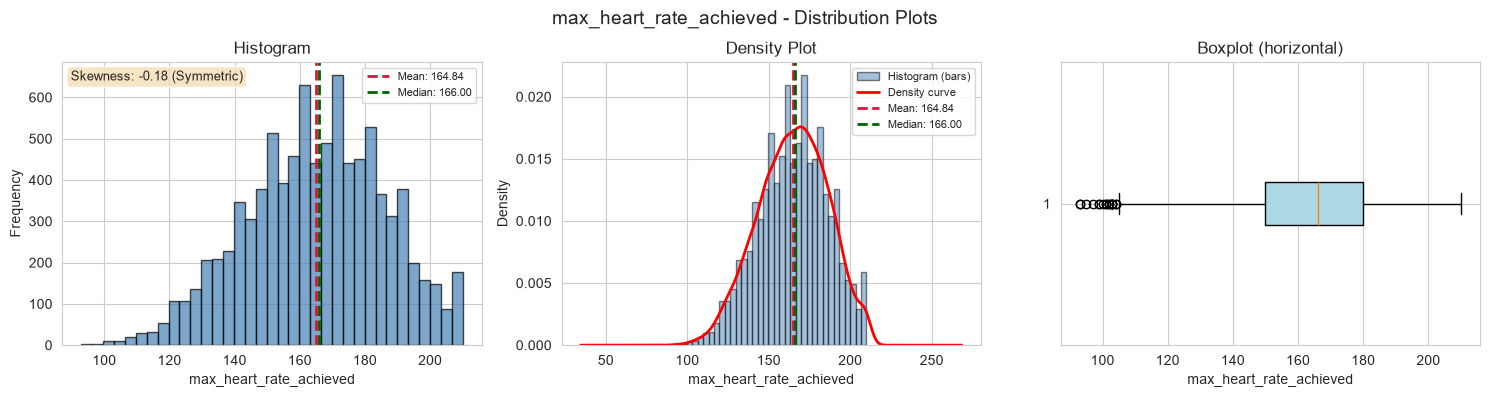

Interpretation: max_heart_rate_achieved
  Shape: Symmetric (Skewness = -0.185)
  Mean = 164.84 | Median = 166.00 | difference = 1.16 (low -> symmetric)
  IQR = 30.00 (Q1 = 150.00, Q3 = 180.00)
  Outlier bounds: below 105.00 or above 225.00
  Outliers: 17 patients (0.2%)
  Comment: Near-symmetric with a very slight left lean (skew ~ -0.19). Only 17 low-side outliers (below 105) - patients whose exercise capacity is limited, possibly by heart disease.



In [21]:
# ===== MAX_HEART_RATE_ACHIEVED =====
info = plot_distribution("max_heart_rate_achieved")
print_interpretation("max_heart_rate_achieved", info, comments["max_heart_rate_achieved"])

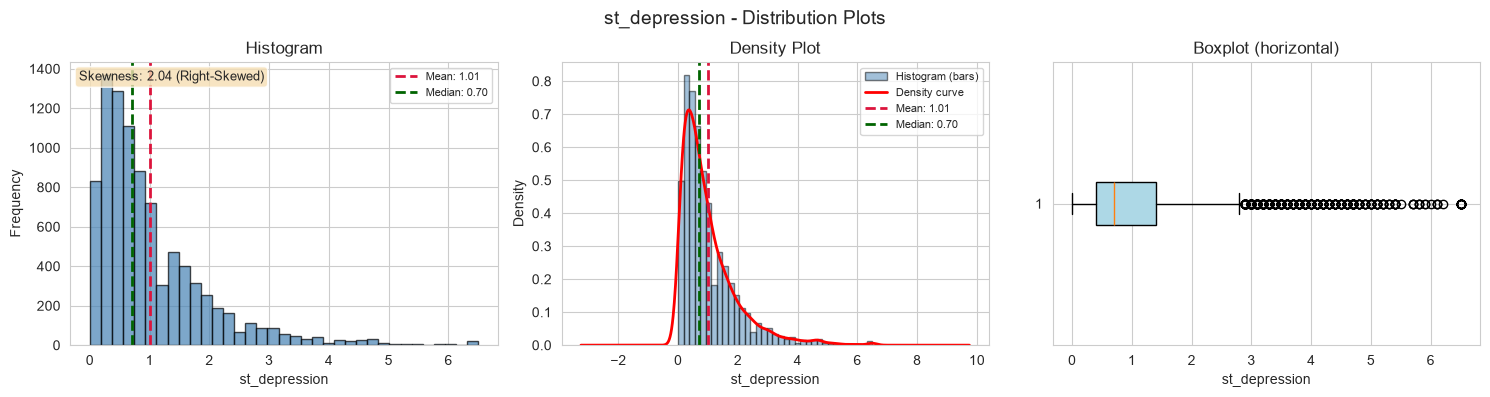

Interpretation: st_depression
  Shape: Right-Skewed (Skewness = 2.041)
  Mean = 1.01 | Median = 0.70 | difference = 0.31 (mean > median -> Right-Skewed)
  IQR = 1.00 (Q1 = 0.40, Q3 = 1.40)
  Outlier bounds: below -1.10 or above 2.90
  Outliers: 485 patients (5.4%)
  Comment: STRONGLY RIGHT-SKEWED (skew ~ 2.04): most patients have small values (median 0.70) but a few have very large ones. 485 outliers (5.4%) - the most of any feature. High ST depression is a classic ECG sign of heart disease, so these outliers are clinically meaningful.



In [22]:
# ===== ST_DEPRESSION =====
info = plot_distribution("st_depression")
print_interpretation("st_depression", info, comments["st_depression"])

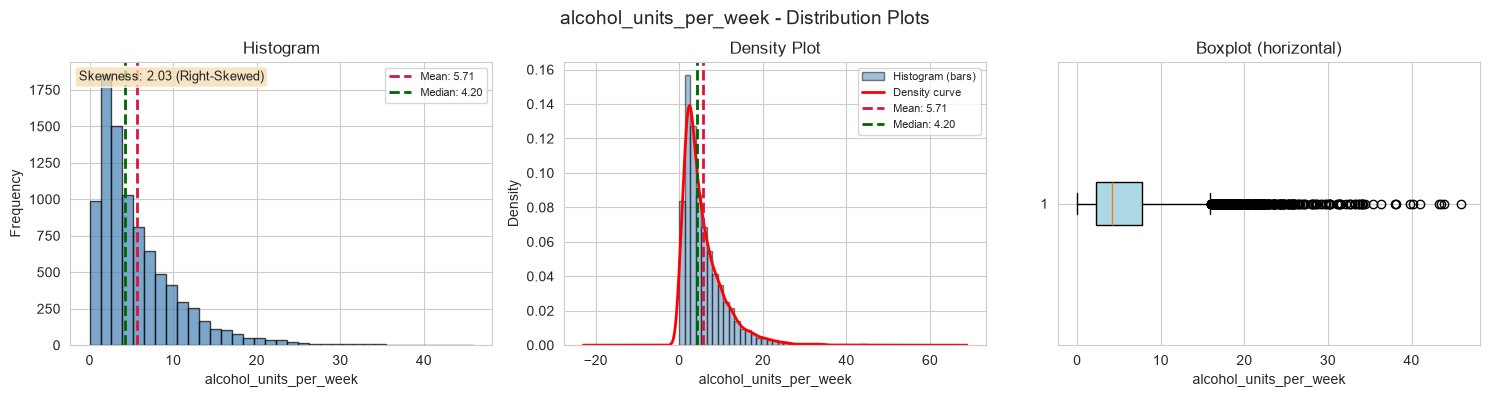

Interpretation: alcohol_units_per_week
  Shape: Right-Skewed (Skewness = 2.027)
  Mean = 5.71 | Median = 4.20 | difference = 1.51 (mean > median -> Right-Skewed)
  IQR = 5.50 (Q1 = 2.20, Q3 = 7.70)
  Outlier bounds: below -6.05 or above 15.95
  Outliers: 431 patients (4.8%)
  Comment: STRONGLY RIGHT-SKEWED (skew ~ 2.03): most people drink little (median 4.2 units/week) but a minority drink a lot. 431 outliers (4.8%) lie above 16 units/week.



In [23]:
# ===== ALCOHOL_UNITS_PER_WEEK =====
info = plot_distribution("alcohol_units_per_week")
print_interpretation("alcohol_units_per_week", info, comments["alcohol_units_per_week"])

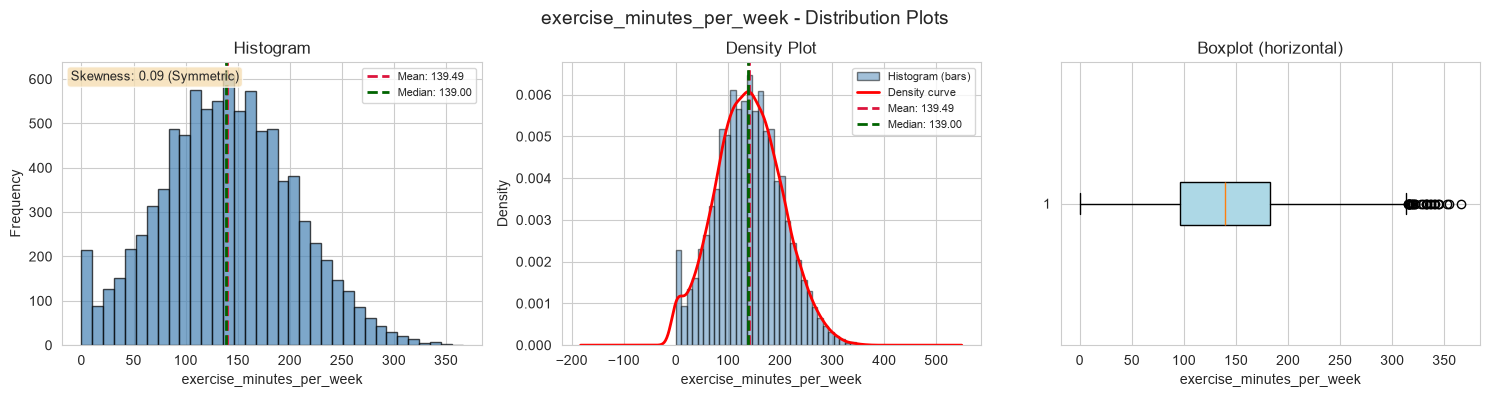

Interpretation: exercise_minutes_per_week
  Shape: Symmetric (Skewness = 0.094)
  Mean = 139.49 | Median = 139.00 | difference = 0.49 (low -> symmetric)
  IQR = 87.00 (Q1 = 96.00, Q3 = 183.00)
  Outlier bounds: below -34.50 or above 313.50
  Outliers: 27 patients (0.3%)
  Comment: Mean ~ median (both ~139), so the middle of the data is symmetric - but the mode is 0, meaning many patients do no exercise at all. The 27 high-side outliers are very active people (above 314 minutes/week).



In [24]:
# ===== EXERCISE_MINUTES_PER_WEEK =====
info = plot_distribution("exercise_minutes_per_week")
print_interpretation("exercise_minutes_per_week", info, comments["exercise_minutes_per_week"])

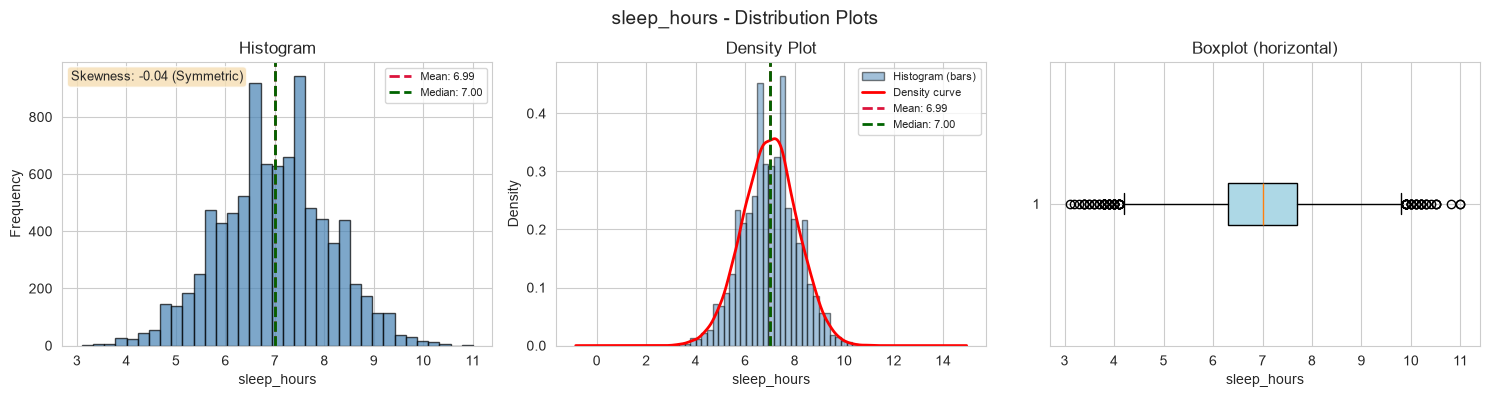

Interpretation: sleep_hours
  Shape: Symmetric (Skewness = -0.042)
  Mean = 6.99 | Median = 7.00 | difference = 0.01 (low -> symmetric)
  IQR = 1.40 (Q1 = 6.30, Q3 = 7.70)
  Outlier bounds: below 4.20 or above 9.80
  Outliers: 86 patients (1.0%)
  Comment: Symmetric around 7 hours (the recommended sleep duration). The 86 outliers sit at both extremes: very little sleep (below 4.2h) and very long sleep (above 9.8h).



In [25]:
# ===== SLEEP_HOURS =====
info = plot_distribution("sleep_hours")
print_interpretation("sleep_hours", info, comments["sleep_hours"])

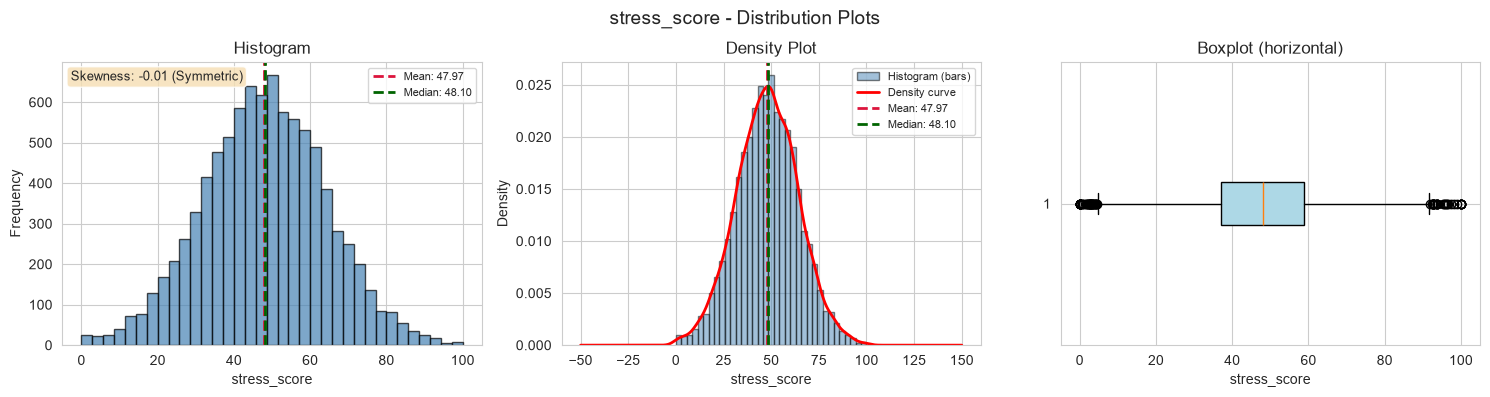

Interpretation: stress_score
  Shape: Symmetric (Skewness = -0.013)
  Mean = 47.97 | Median = 48.10 | difference = 0.13 (low -> symmetric)
  IQR = 21.80 (Q1 = 37.10, Q3 = 58.90)
  Outlier bounds: below 4.40 or above 91.60
  Outliers: 71 patients (0.8%)
  Comment: Symmetric around 48 (the middle of the 0-100 scale) with skew ~ -0.01. Only 71 outliers (0.8%), split on both sides.



In [26]:
# ===== STRESS_SCORE =====
info = plot_distribution("stress_score")
print_interpretation("stress_score", info, comments["stress_score"])

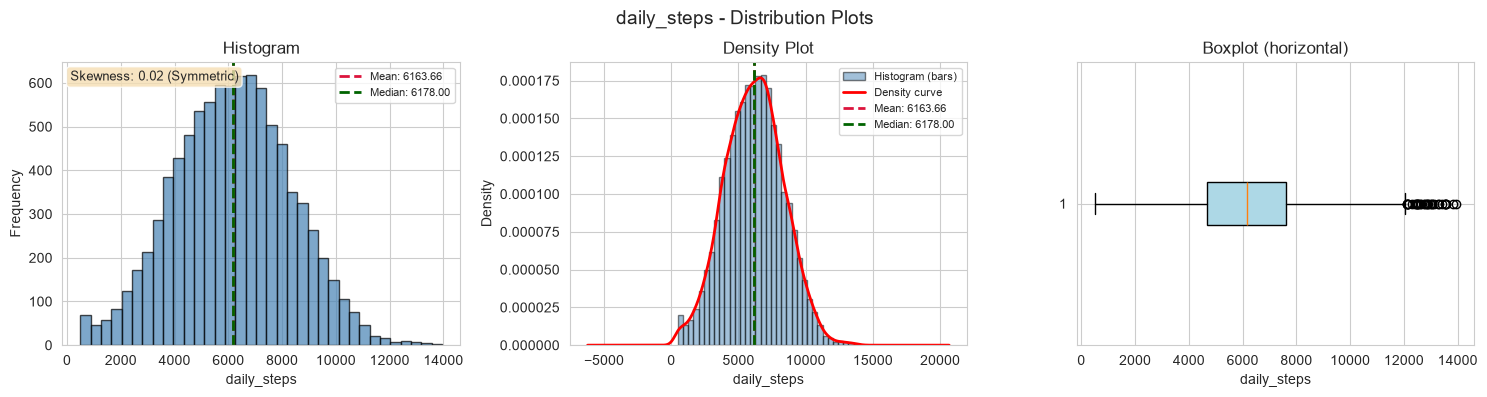

Interpretation: daily_steps
  Shape: Symmetric (Skewness = 0.025)
  Mean = 6163.66 | Median = 6178.00 | difference = 14.34 (low -> symmetric)
  IQR = 2974.75 (Q1 = 4658.00, Q3 = 7632.75)
  Outlier bounds: below 195.88 or above 12094.88
  Outliers: 32 patients (0.4%)
  Comment: Symmetric around ~6164 steps with the widest spread of all features (std ~ 2171). The mode of 500 shows many patients are very sedentary, and the 32 low-side outliers have near-zero step counts.



In [27]:
# ===== DAILY_STEPS =====
info = plot_distribution("daily_steps")
print_interpretation("daily_steps", info, comments["daily_steps"])

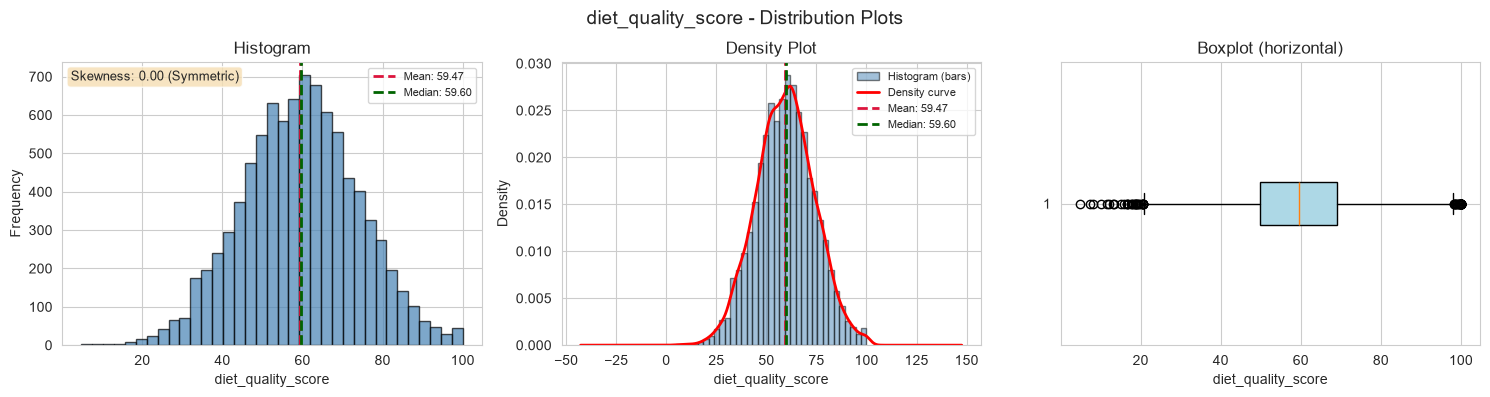

Interpretation: diet_quality_score
  Shape: Symmetric (Skewness = 0.001)
  Mean = 59.47 | Median = 59.60 | difference = 0.13 (low -> symmetric)
  IQR = 19.40 (Q1 = 49.70, Q3 = 69.10)
  Outlier bounds: below 20.60 or above 98.20
  Outliers: 69 patients (0.8%)
  Comment: Perfectly symmetric (skew ~ 0.00) around 59.5 (middle of the 0-100 scale). The 69 outliers on both sides represent the extremes of diet quality.



In [28]:
# ===== DIET_QUALITY_SCORE =====
info = plot_distribution("diet_quality_score")
print_interpretation("diet_quality_score", info, comments["diet_quality_score"])

### Summary table: shape and outliers for every numerical feature

In [29]:
# summary table of the Part 3 results
summary_rows = []

for col in numerical_features:
    d = df[col]

    skew_val = d.skew()
    if abs(skew_val) < 0.5:
        shape = "Symmetric"
    elif skew_val > 0:
        shape = "Right-Skewed"
    else:
        shape = "Left-Skewed"

    q1, q3 = d.quantile(0.25), d.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = len(d[(d < lower) | (d > upper)])

    summary_rows.append([
        col, round(skew_val, 3), shape, n_out, round(n_out / len(d) * 100, 2),
    ])

shape_summary = pd.DataFrame(
    summary_rows,
    columns=["Feature", "Skewness", "Shape", "Outliers (count)", "Outliers (%)"],
)
shape_summary

,Feature,Skewness,Shape,Outliers (count),Outliers (%)
0,age,-0.022,Symmetric,0,0.00
1,resting_bp_systolic,0.068,Symmetric,66,0.73
2,resting_bp_diastolic,0.009,Symmetric,75,0.83
3,cholesterol_total,0.004,Symmetric,50,0.56
4,hdl,0.020,Symmetric,63,0.70
5,ldl,0.045,Symmetric,34,0.38
6,triglycerides,0.126,Symmetric,42,0.47
7,fasting_blood_sugar,0.041,Symmetric,32,0.36
8,hba1c,0.029,Symmetric,10,0.11
9,bmi,0.092,Symmetric,39,0.43


### Part 3: Key observations

- **17 out of 19 features are symmetric** (skewness between -0.5 and +0.5) and their mean is
  almost equal to the median, so the typical patient is close to the average.
- Only two features are clearly **right-skewed**:
  - `st_depression` (skew ≈ 2.04) with **5.4% outliers** (the most of any feature).
  - `alcohol_units_per_week` (skew ≈ 2.03) with **4.8% outliers**.
- All other features have **less than ~1% outliers**, so the dataset is quite clean and the
  outliers are the genuine extremes of patient health (hypertension, diabetes, obesity, etc.),
  not data-entry mistakes.
- The two right-skewed features plus the zero-spikes (`exercise_minutes_per_week`, `daily_steps`
  mode = 500) are the most interesting for later prediction, because they capture the extremes
  of patient behaviour and clinical risk.

# Part 4: Categorical Variable Analysis

Categorical variables cannot be averaged like numbers, so we study them differently.
For each categorical feature we make:

1. **A frequency table:** how many patients are in each category (count + percentage).
2. **A bar chart:** height of each bar = number of patients in that category.
3. **A pie chart:** each slice = the proportion (percentage) of that category.

Then we identify the **most common category** and comment on any **imbalance** in the data.

In [30]:
# helper functions used for every categorical feature

# readable labels for the True/False and 0/1 columns
label_map = {
    "exercise_induced_angina": {True: "Yes", False: "No"},
    "family_history":          {True: "Yes", False: "No"},
    "wearable_owner":          {True: "Yes", False: "No"},
    "has_heart_disease":       {1: "Yes", 0: "No"},
}

def plot_categorical(col):
    # draws a bar chart and a pie chart, returns the frequency table
    if col in label_map:
        counts = df[col].map(label_map[col]).value_counts()
    else:
        counts = df[col].value_counts()

    # Frequency table: count + percentage
    freq = pd.DataFrame({"Count": counts,
                         "Percent": (counts / len(df) * 100).round(2)})

    # bar chart + pie chart
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    fig.suptitle(f"{col} - Bar & Pie Chart", fontsize=14)

    # --- Bar chart ---
    axes[0].bar(counts.index, counts.values, color='steelblue', edgecolor='black')
    axes[0].set_title("Bar Chart")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")
    axes[0].set_ylim(0, counts.max() * 1.2)          # leave room for the bar labels
    axes[0].tick_params(axis='x', rotation=10)

    # count on top of each bar
    for i, v in enumerate(counts.values):
        axes[0].text(i, v + counts.max() * 0.02, str(v), ha='center', fontsize=10)

    # --- Pie chart ---
    axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
                startangle=90, colors=sns.color_palette("viridis", len(counts)))
    axes[1].set_title("Pie Chart")

    plt.tight_layout()
    fig.subplots_adjust(top=0.82)
    plt.show()

    return freq

def print_categorical(col, freq, comment):
    # prints the interpretation block for one categorical feature
    most = freq.index[0]                 # most common category
    most_count = int(freq["Count"].iloc[0])
    most_pct = float(freq["Percent"].iloc[0])
    print(f"Interpretation: {col}")
    print(f"  Most common category: {most} ({most_count} patients, {most_pct:.1f}%)")
    print(f"  Frequency table:")
    print(freq.to_string())
    print(f"  Comment: {comment}")
    print()

In [31]:
# A dictionary of the interpretation comments for every categorical feature
cat_comments = {
    'sex': 'Nearly balanced - Male (52.6%) vs Female (47.4%). No real imbalance, so sex should not bias the analysis.',
    'chest_pain_type': 'ASYMMETRIC - Asymptomatic (47.4%) dominates; it has more patients than the other three categories combined. This is clinically important: many heart-disease patients have NO chest pain, so this variable alone is not enough to judge risk.',
    'exercise_induced_angina': 'Imbalanced - 77.1% No vs 22.9% Yes. The minority group (angina triggered by exercise) is still large enough (2062 patients) to study.',
    'family_history': 'Imbalanced - 72.8% No vs 27.3% Yes. Only about one in four patients has a family history of heart disease.',
    'smoker_status': 'Never (55.3%) is the most common, followed by Former (27.2%) and Current (17.5%). Reasonable spread, but current smokers are a clear minority.',
    'wearable_owner': 'Fairly balanced - 55.7% No vs 44.3% Yes. Good spread, so owning a wearable can be fairly compared between groups.',
    'has_heart_disease': "Imbalanced - 69.7% No vs 30.3% Yes. This is the TARGET variable; the imbalance matters when we build a prediction model later (the model would otherwise just learn to predict 'No').",
}

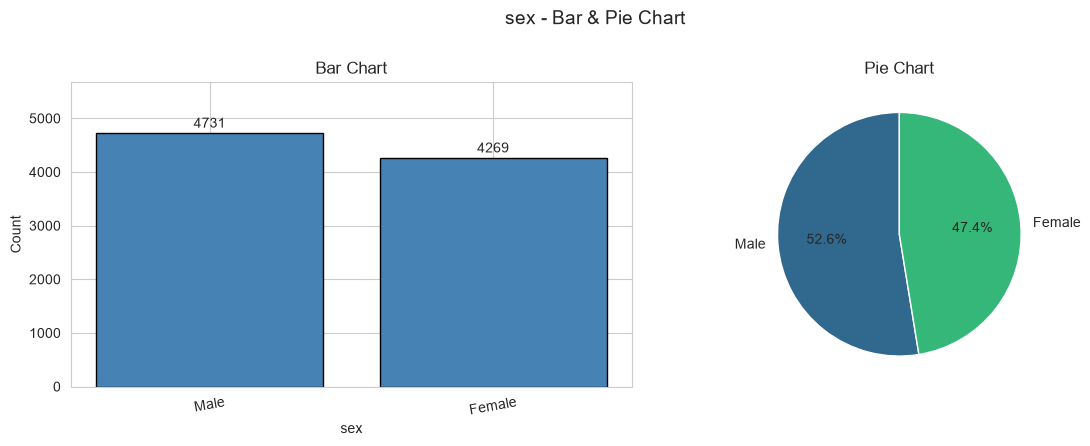

Interpretation: sex
  Most common category: Male (4731 patients, 52.6%)
  Frequency table:
        Count  Percent
sex                   
Male     4731    52.57
Female   4269    47.43
  Comment: Nearly balanced - Male (52.6%) vs Female (47.4%). No real imbalance, so sex should not bias the analysis.



In [32]:
# ===== SEX =====
freq = plot_categorical("sex")
print_categorical("sex", freq, cat_comments["sex"])

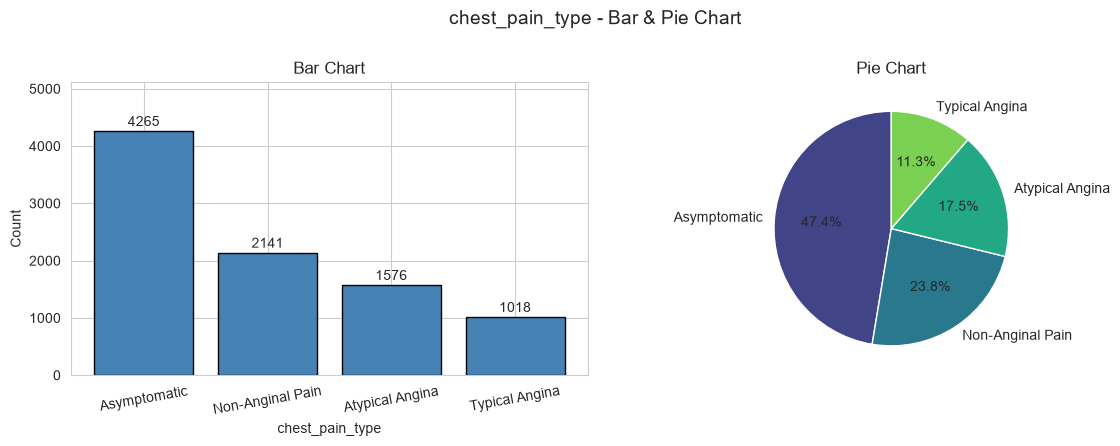

Interpretation: chest_pain_type
  Most common category: Asymptomatic (4265 patients, 47.4%)
  Frequency table:
                  Count  Percent
chest_pain_type                 
Asymptomatic       4265    47.39
Non-Anginal Pain   2141    23.79
Atypical Angina    1576    17.51
Typical Angina     1018    11.31
  Comment: ASYMMETRIC - Asymptomatic (47.4%) dominates; it has more patients than the other three categories combined. This is clinically important: many heart-disease patients have NO chest pain, so this variable alone is not enough to judge risk.



In [33]:
# ===== CHEST_PAIN_TYPE =====
freq = plot_categorical("chest_pain_type")
print_categorical("chest_pain_type", freq, cat_comments["chest_pain_type"])

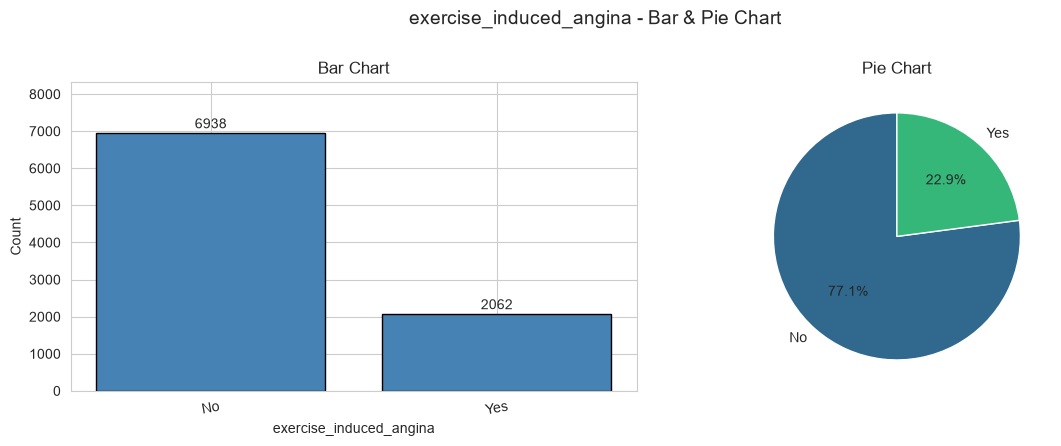

Interpretation: exercise_induced_angina
  Most common category: No (6938 patients, 77.1%)
  Frequency table:
                         Count  Percent
exercise_induced_angina                
No                        6938    77.09
Yes                       2062    22.91
  Comment: Imbalanced - 77.1% No vs 22.9% Yes. The minority group (angina triggered by exercise) is still large enough (2062 patients) to study.



In [34]:
# ===== EXERCISE_INDUCED_ANGINA =====
freq = plot_categorical("exercise_induced_angina")
print_categorical("exercise_induced_angina", freq, cat_comments["exercise_induced_angina"])

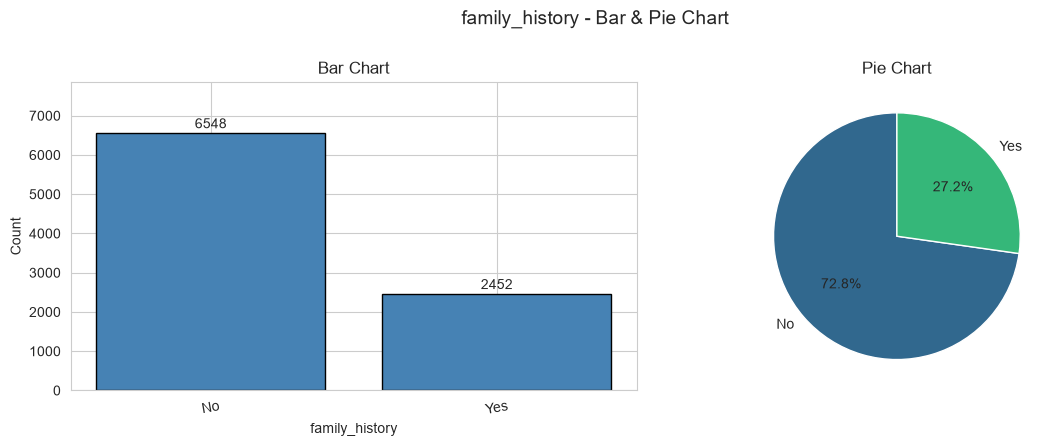

Interpretation: family_history
  Most common category: No (6548 patients, 72.8%)
  Frequency table:
                Count  Percent
family_history                
No               6548    72.76
Yes              2452    27.24
  Comment: Imbalanced - 72.8% No vs 27.3% Yes. Only about one in four patients has a family history of heart disease.



In [35]:
# ===== FAMILY_HISTORY =====
freq = plot_categorical("family_history")
print_categorical("family_history", freq, cat_comments["family_history"])

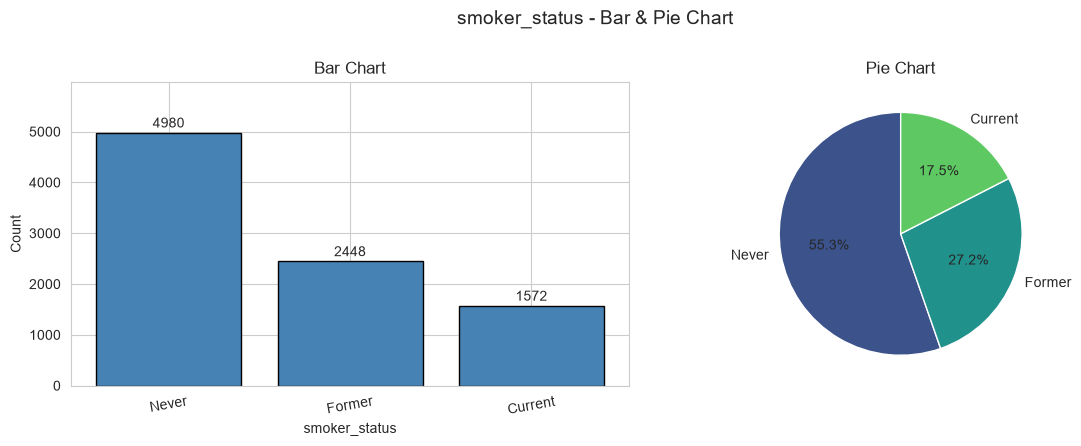

Interpretation: smoker_status
  Most common category: Never (4980 patients, 55.3%)
  Frequency table:
               Count  Percent
smoker_status                
Never           4980    55.33
Former          2448    27.20
Current         1572    17.47
  Comment: Never (55.3%) is the most common, followed by Former (27.2%) and Current (17.5%). Reasonable spread, but current smokers are a clear minority.



In [36]:
# ===== SMOKER_STATUS =====
freq = plot_categorical("smoker_status")
print_categorical("smoker_status", freq, cat_comments["smoker_status"])

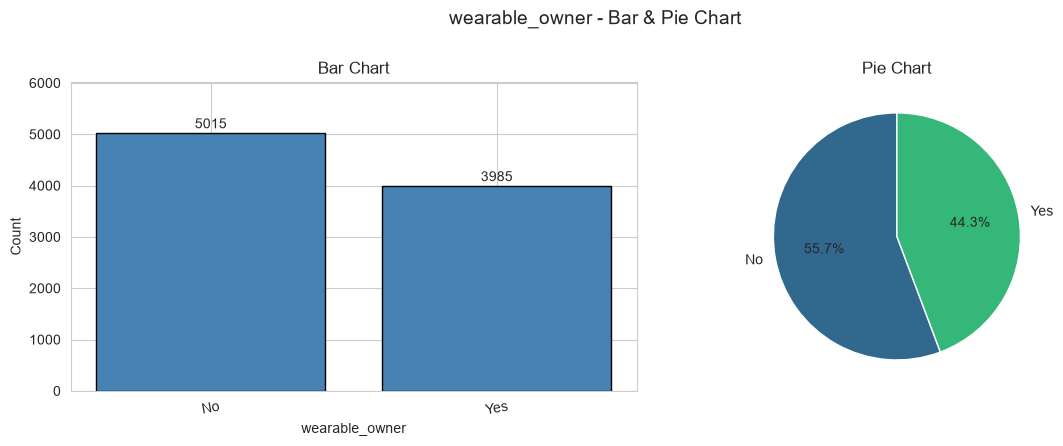

Interpretation: wearable_owner
  Most common category: No (5015 patients, 55.7%)
  Frequency table:
                Count  Percent
wearable_owner                
No               5015    55.72
Yes              3985    44.28
  Comment: Fairly balanced - 55.7% No vs 44.3% Yes. Good spread, so owning a wearable can be fairly compared between groups.



In [37]:
# ===== WEARABLE_OWNER =====
freq = plot_categorical("wearable_owner")
print_categorical("wearable_owner", freq, cat_comments["wearable_owner"])

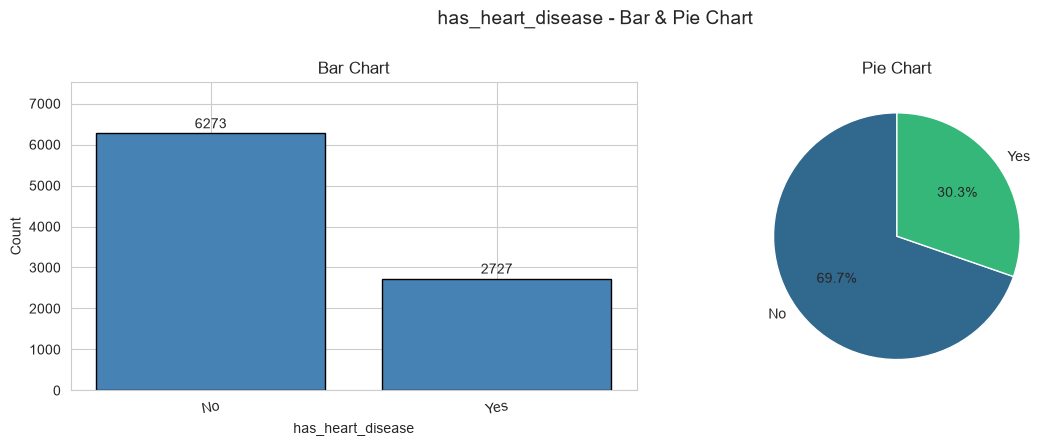

Interpretation: has_heart_disease
  Most common category: No (6273 patients, 69.7%)
  Frequency table:
                   Count  Percent
has_heart_disease                
No                  6273     69.7
Yes                 2727     30.3
  Comment: Imbalanced - 69.7% No vs 30.3% Yes. This is the TARGET variable; the imbalance matters when we build a prediction model later (the model would otherwise just learn to predict 'No').



In [38]:
# ===== HAS_HEART_DISEASE =====
freq = plot_categorical("has_heart_disease")
print_categorical("has_heart_disease", freq, cat_comments["has_heart_disease"])

### Part 4: Key observations

- `sex` and `wearable_owner` are nearly **balanced**, so comparisons between groups are fair.
- `chest_pain_type`, `exercise_induced_angina`, `family_history`, `smoker_status` are
  **imbalanced**; one category dominates in each.
- The **target variable** `has_heart_disease` is imbalanced (30.3% have the disease).
  This is the most important imbalance: a predictive model built later will need to
  handle it (e.g. with class weights or careful evaluation metrics).

# Part 5: Relationships Between Variables

Now we explore how features relate **to each other** and **to the target variable**
(`has_heart_disease`). Two different kinds of plots are needed:

1. **Scatterplots** for pairs of *numerical* variables (e.g. age vs cholesterol). We colour
   the dots by heart disease so we can see whether the two groups fall in different parts
   of the cloud.
2. **Boxplots** (and **count/proportion plots**) when one variable is the binary target.
   A scatterplot would only draw two vertical strips of points, so a boxplot per group
   shows the difference in the middle and spread much more clearly.

For every numerical pair we also report the **Pearson correlation coefficient** `r`:

| |r| value | Strength |
|---|---|---|
| 0.00 – 0.20 | very weak / negligible |
| 0.20 – 0.40 | weak |
| 0.40 – 0.60 | moderate |
| 0.60 – 0.80 | strong |
| 0.80 – 1.00 | very strong |

`r > 0` means the variables move in the same direction, `r < 0` means they move in opposite
directions.

In [39]:
# preparation for Part 5

# readable labels for plot legends (the original column is left untouched)
df["hd_label"] = df["has_heart_disease"].map({1: "Yes (disease)", 0: "No (no disease)"})

print("Ready for Part 5 - Relationships Between Variables")

Ready for Part 5 - Relationships Between Variables


### 5.1 Age vs Total Cholesterol (colored by heart disease)

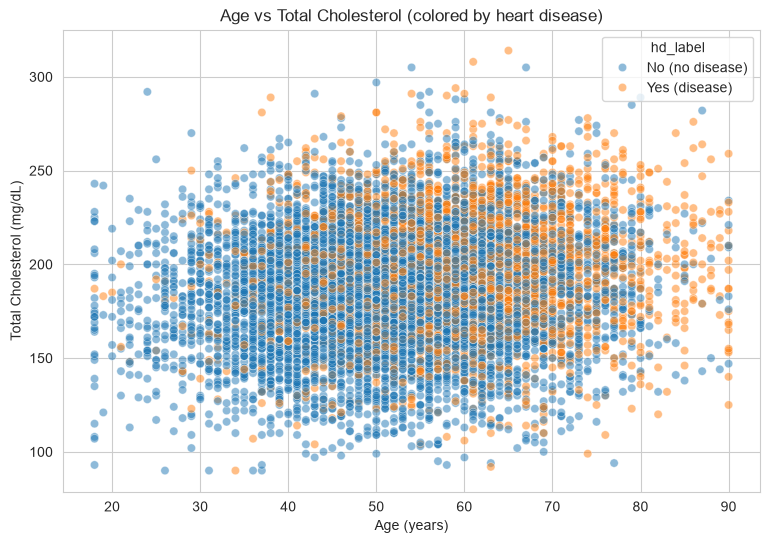

Pearson correlation (age, cholesterol) = 0.128
Interpretation: age and cholesterol are only WEAKLY related (r = 0.128) - the points form a wide cloud with no clear line. Still, patients with disease tend to sit a bit higher: on average they are older (59.7 vs 51.5 years) and have slightly higher cholesterol (197 vs 185 mg/dL).


In [40]:
# ===== Plot 1: Age vs Total Cholesterol =====
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="age", y="cholesterol_total", hue="hd_label", alpha=0.5)
plt.title("Age vs Total Cholesterol (colored by heart disease)")
plt.xlabel("Age (years)")
plt.ylabel("Total Cholesterol (mg/dL)")
plt.show()

corr = df["age"].corr(df["cholesterol_total"])
print(f"Pearson correlation (age, cholesterol) = {corr:.3f}")
print("Interpretation: age and cholesterol are only WEAKLY related (r = 0.128) - the points form a "
      "wide cloud with no clear line. Still, patients with disease tend to sit a bit higher: on "
      "average they are older (59.7 vs 51.5 years) and have slightly higher cholesterol (197 vs 185 mg/dL).")

### 5.2 Same scatterplot, split into Males and Females

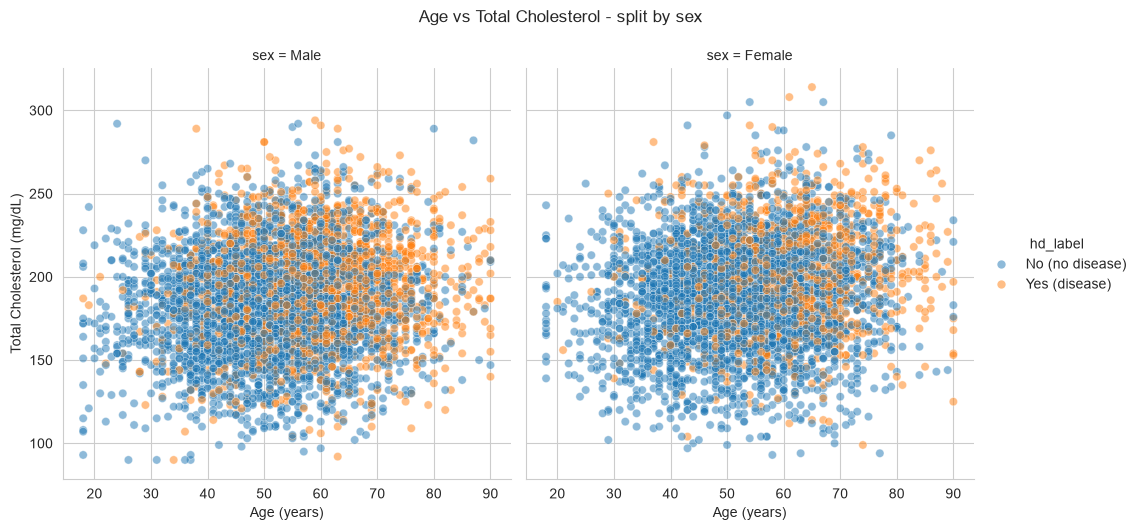

Disease rate: Male = 35.4% | Female = 24.7%
Interpretation: the age-cholesterol pattern looks similar in both sexes, but males have a higher disease rate overall (35.4% vs 24.7%).


In [41]:
# ===== Plot 2: Age vs Total Cholesterol, split by sex =====
g = sns.relplot(data=df, x="age", y="cholesterol_total", hue="hd_label",
                col="sex", alpha=0.5)
g.set_axis_labels("Age (years)", "Total Cholesterol (mg/dL)")
g.figure.suptitle("Age vs Total Cholesterol - split by sex", y=1.05)
plt.show()

rate_male = df.loc[df["sex"] == "Male", "has_heart_disease"].mean() * 100
rate_female = df.loc[df["sex"] == "Female", "has_heart_disease"].mean() * 100
print(f"Disease rate: Male = {rate_male:.1f}% | Female = {rate_female:.1f}%")
print("Interpretation: the age-cholesterol pattern looks similar in both sexes, but males have a "
      "higher disease rate overall (35.4% vs 24.7%).")

### 5.3 HDL (good cholesterol) vs LDL (bad cholesterol)

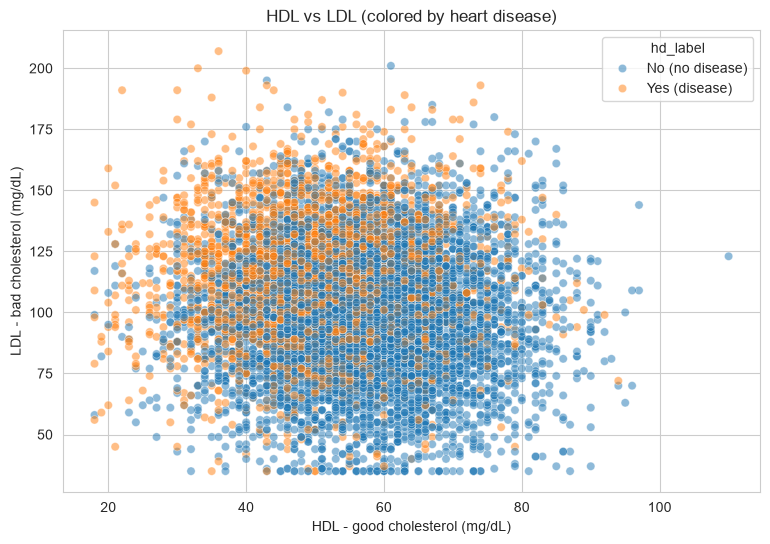

Pearson correlation (hdl, ldl) = -0.082
Mean HDL: no disease = 57.3 | with disease = 50.5
Mean LDL: no disease = 98.5 | with disease = 114.4
Interpretation: HDL and LDL are almost uncorrelated (r = -0.082) - they are independent cholesterol measurements. The two groups separate clearly though: patients with disease have LOWER HDL (50.5 vs 57.3) and HIGHER LDL (114.4 vs 98.5). HDL is protective, LDL is harmful.


In [42]:
# ===== Plot 3: HDL vs LDL =====
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="hdl", y="ldl", hue="hd_label", alpha=0.5)
plt.title("HDL vs LDL (colored by heart disease)")
plt.xlabel("HDL - good cholesterol (mg/dL)")
plt.ylabel("LDL - bad cholesterol (mg/dL)")
plt.show()

corr = df["hdl"].corr(df["ldl"])
hdl_no, hdl_yes = df.groupby("has_heart_disease")["hdl"].mean()
ldl_no, ldl_yes = df.groupby("has_heart_disease")["ldl"].mean()
print(f"Pearson correlation (hdl, ldl) = {corr:.3f}")
print(f"Mean HDL: no disease = {hdl_no:.1f} | with disease = {hdl_yes:.1f}")
print(f"Mean LDL: no disease = {ldl_no:.1f} | with disease = {ldl_yes:.1f}")
print("Interpretation: HDL and LDL are almost uncorrelated (r = -0.082) - they are independent "
      "cholesterol measurements. The two groups separate clearly though: patients with disease have "
      "LOWER HDL (50.5 vs 57.3) and HIGHER LDL (114.4 vs 98.5). HDL is protective, LDL is harmful.")

### 5.4 Age vs BMI, split into Males and Females

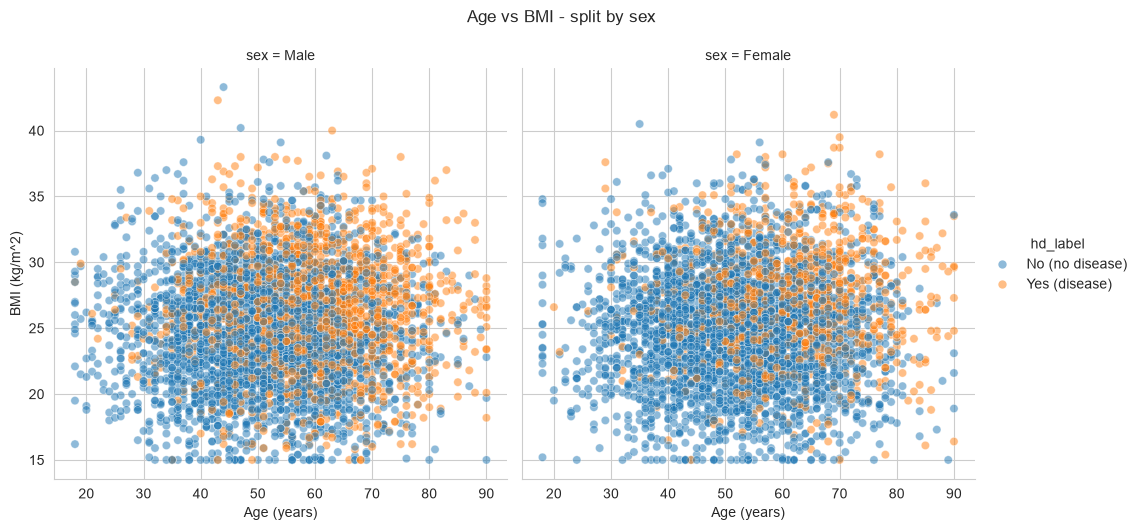

Pearson correlation (age, bmi) = 0.039
Interpretation: age and BMI are basically INDEPENDENT (r = 0.039) - growing older does not automatically mean a higher BMI. In both sexes the disease group tends to have higher BMI.


In [43]:
# ===== Plot 4: Age vs BMI, split by sex =====
g = sns.relplot(data=df, x="age", y="bmi", hue="hd_label", col="sex", alpha=0.5)
g.set_axis_labels("Age (years)", "BMI (kg/m^2)")
g.figure.suptitle("Age vs BMI - split by sex", y=1.05)
plt.show()

corr = df["age"].corr(df["bmi"])
print(f"Pearson correlation (age, bmi) = {corr:.3f}")
print("Interpretation: age and BMI are basically INDEPENDENT (r = 0.039) - growing older does not "
      "automatically mean a higher BMI. In both sexes the disease group tends to have higher BMI.")

### 5.5 BMI vs heart disease

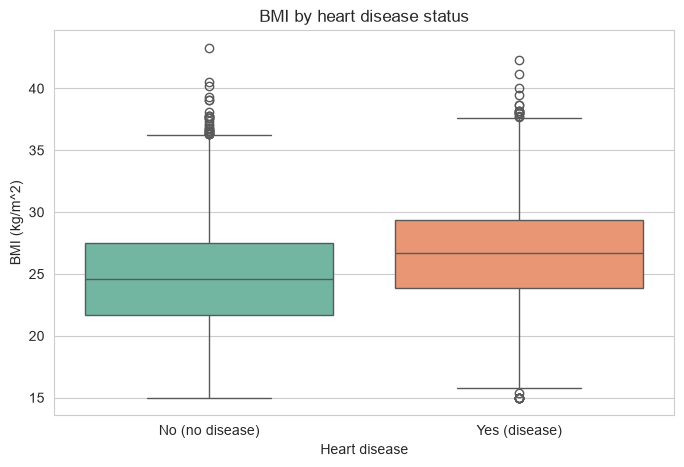

Mean BMI: no disease = 24.65 | with disease = 26.68
Pearson correlation (bmi, disease) = 0.213
Interpretation: patients with disease have a clearly higher average BMI (26.7 vs 24.7). The whole box shifts up, so excess weight is associated with heart disease.


In [44]:
# ===== Plot 5: BMI by heart disease (boxplot) =====
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="hd_label", y="bmi", palette="Set2")
plt.title("BMI by heart disease status")
plt.xlabel("Heart disease")
plt.ylabel("BMI (kg/m^2)")
plt.show()

bmi_no, bmi_yes = df.groupby("has_heart_disease")["bmi"].mean()
corr = df["bmi"].corr(df["has_heart_disease"])
print(f"Mean BMI: no disease = {bmi_no:.2f} | with disease = {bmi_yes:.2f}")
print(f"Pearson correlation (bmi, disease) = {corr:.3f}")
print("Interpretation: patients with disease have a clearly higher average BMI (26.7 vs 24.7). "
      "The whole box shifts up, so excess weight is associated with heart disease.")

### 5.6 Chest pain type vs heart disease

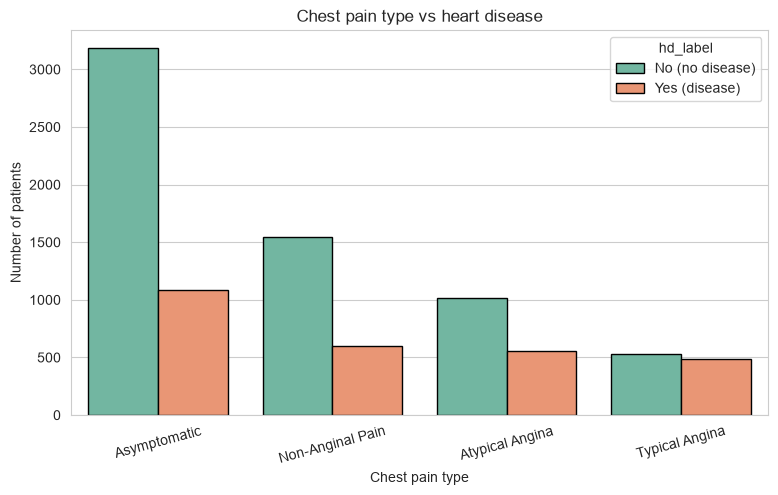

Disease rate (%) within each chest pain type:
chest_pain_type
Asymptomatic        25.4
Atypical Angina     35.5
Non-Anginal Pain    27.8
Typical Angina      47.9
Name: has_heart_disease, dtype: float64
Interpretation: Typical Angina has by far the highest disease rate (47.9%), followed by Atypical Angina (35.5%), Non-Anginal Pain (27.8%) and Asymptomatic (25.4%). So the TYPE of chest pain is informative - but note Asymptomatic still contains the most patients overall.


In [45]:
# ===== Plot 6: Chest pain type vs heart disease (countplot) =====
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="chest_pain_type", hue="hd_label", palette="Set2", edgecolor="black")
plt.title("Chest pain type vs heart disease")
plt.xlabel("Chest pain type")
plt.ylabel("Number of patients")
plt.xticks(rotation=15)
plt.show()

# percentage of patients WITH disease inside each chest-pain group
rates = (df.groupby("chest_pain_type")["has_heart_disease"].mean() * 100).round(1)
print("Disease rate (%) within each chest pain type:")
print(rates)
print("Interpretation: Typical Angina has by far the highest disease rate (47.9%), followed by "
      "Atypical Angina (35.5%), Non-Anginal Pain (27.8%) and Asymptomatic (25.4%). So the TYPE of "
      "chest pain is informative - but note Asymptomatic still contains the most patients overall.")

### 5.7 Fasting blood sugar vs heart disease

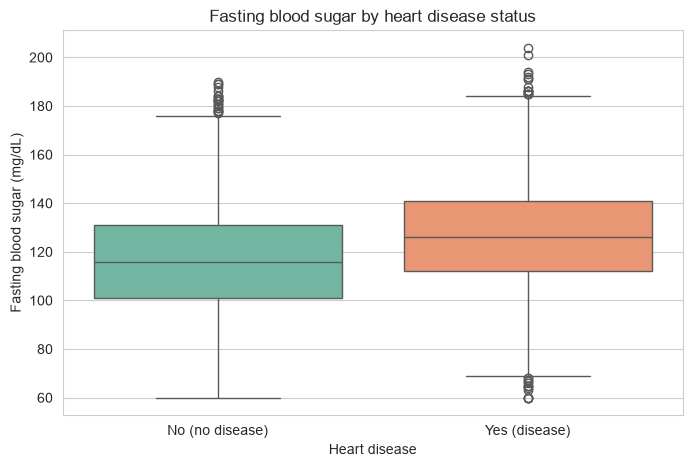

Mean sugar: no disease = 116.43 | with disease = 126.46
Pearson correlation (sugar, disease) = 0.202
Interpretation: patients with disease have clearly higher fasting blood sugar (126.5 vs 116.4 mg/dL). High sugar / diabetes is a known risk factor for heart disease.


In [46]:
# ===== Plot 7: Fasting blood sugar by heart disease (boxplot) =====
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="hd_label", y="fasting_blood_sugar", palette="Set2")
plt.title("Fasting blood sugar by heart disease status")
plt.xlabel("Heart disease")
plt.ylabel("Fasting blood sugar (mg/dL)")
plt.show()

sugar_no, sugar_yes = df.groupby("has_heart_disease")["fasting_blood_sugar"].mean()
corr = df["fasting_blood_sugar"].corr(df["has_heart_disease"])
print(f"Mean sugar: no disease = {sugar_no:.2f} | with disease = {sugar_yes:.2f}")
print(f"Pearson correlation (sugar, disease) = {corr:.3f}")
print("Interpretation: patients with disease have clearly higher fasting blood sugar (126.5 vs "
      "116.4 mg/dL). High sugar / diabetes is a known risk factor for heart disease.")

### 5.8 Family history vs heart disease

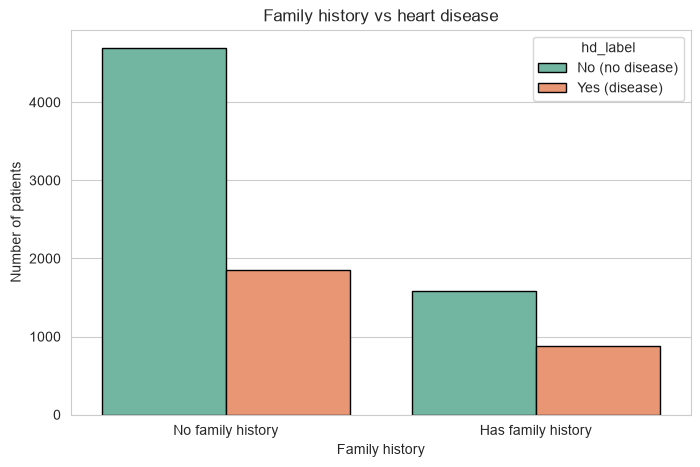

Disease rate: no family history = 28.3% | with family history = 35.6%
Interpretation: patients with a family history of heart disease have a higher disease rate (35.6% vs 28.3%), so family history is a useful risk factor.


In [47]:
# ===== Plot 8: Family history vs heart disease (countplot) =====
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="family_history", hue="hd_label", order=[False, True],
              palette="Set2", edgecolor="black")
plt.xticks([0, 1], ["No family history", "Has family history"])
plt.title("Family history vs heart disease")
plt.xlabel("Family history")
plt.ylabel("Number of patients")
plt.show()

rate_no = df.loc[df["family_history"] == False, "has_heart_disease"].mean() * 100
rate_yes = df.loc[df["family_history"] == True, "has_heart_disease"].mean() * 100
print(f"Disease rate: no family history = {rate_no:.1f}% | with family history = {rate_yes:.1f}%")
print("Interpretation: patients with a family history of heart disease have a higher disease rate "
      "(35.6% vs 28.3%), so family history is a useful risk factor.")

### 5.9 Resting blood pressure (systolic & diastolic) vs heart disease

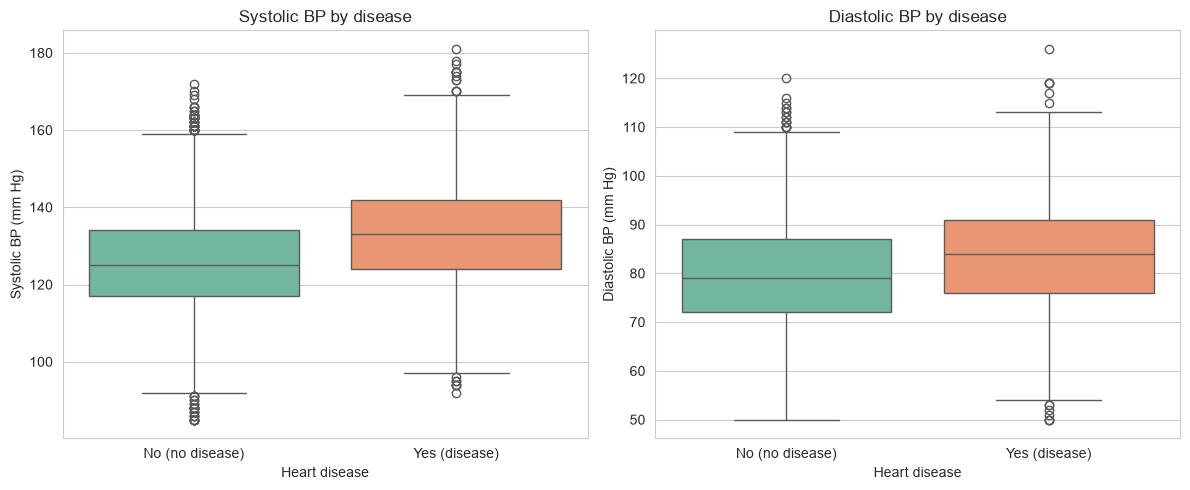

Mean systolic: no disease = 125.6 | with disease = 133.1  (r = 0.249)
Mean diastolic: no disease = 79.4 | with disease = 84.0  (r = 0.193)
Interpretation: both systolic (133.1 vs 125.6) and diastolic (84.0 vs 79.4) blood pressure are higher in patients with disease. High blood pressure (hypertension) is a classic heart-disease risk factor.


In [48]:
# ===== Plot 9: Systolic and Diastolic BP by heart disease =====
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="hd_label", y="resting_bp_systolic", ax=axes[0], palette="Set2")
axes[0].set_title("Systolic BP by disease")
axes[0].set_xlabel("Heart disease")
axes[0].set_ylabel("Systolic BP (mm Hg)")

sns.boxplot(data=df, x="hd_label", y="resting_bp_diastolic", ax=axes[1], palette="Set2")
axes[1].set_title("Diastolic BP by disease")
axes[1].set_xlabel("Heart disease")
axes[1].set_ylabel("Diastolic BP (mm Hg)")

plt.tight_layout()
plt.show()

sys_no, sys_yes = df.groupby("has_heart_disease")["resting_bp_systolic"].mean()
dia_no, dia_yes = df.groupby("has_heart_disease")["resting_bp_diastolic"].mean()
corr_sys = df["resting_bp_systolic"].corr(df["has_heart_disease"])
corr_dia = df["resting_bp_diastolic"].corr(df["has_heart_disease"])
print(f"Mean systolic: no disease = {sys_no:.1f} | with disease = {sys_yes:.1f}  (r = {corr_sys:.3f})")
print(f"Mean diastolic: no disease = {dia_no:.1f} | with disease = {dia_yes:.1f}  (r = {corr_dia:.3f})")
print("Interpretation: both systolic (133.1 vs 125.6) and diastolic (84.0 vs 79.4) blood pressure "
      "are higher in patients with disease. High blood pressure (hypertension) is a classic heart-disease risk factor.")

### 5.10 Smoking status & alcohol vs heart disease

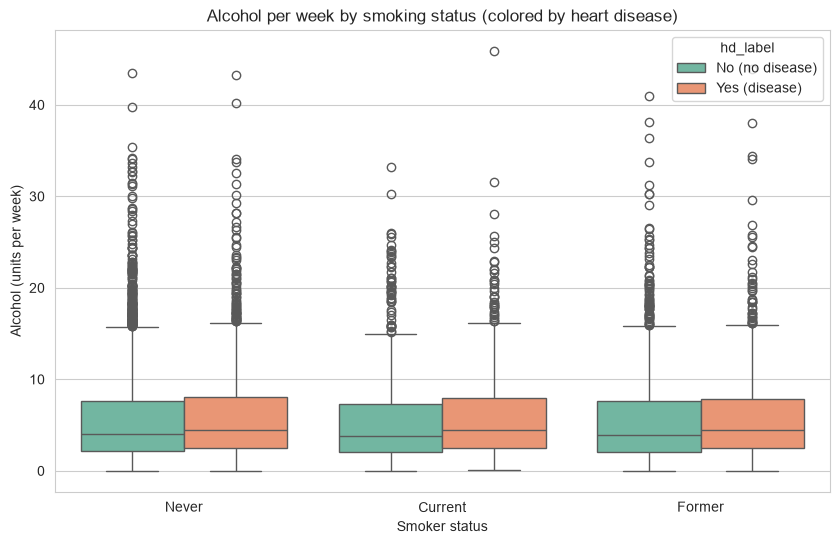

Disease rate (%) by smoker status:
smoker_status
Current    46.4
Former     30.3
Never      25.2
Name: has_heart_disease, dtype: float64
Pearson correlation (alcohol, disease) = 0.041
Interpretation: Current smokers have the HIGHEST disease rate (46.4%), then Former (30.3%) and Never smokers (25.2%). Alcohol is a much weaker factor: its correlation with disease is only 0.041 and the median alcohol levels look similar across smoker groups.


In [49]:
# ===== Plot 10: Alcohol per week by smoking status, colored by disease =====
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="smoker_status", y="alcohol_units_per_week", hue="hd_label", palette="Set2")
plt.title("Alcohol per week by smoking status (colored by heart disease)")
plt.xlabel("Smoker status")
plt.ylabel("Alcohol (units per week)")
plt.show()

rates = (df.groupby("smoker_status")["has_heart_disease"].mean() * 100).round(1)
print("Disease rate (%) by smoker status:")
print(rates)
corr_alc = df["alcohol_units_per_week"].corr(df["has_heart_disease"])
print(f"Pearson correlation (alcohol, disease) = {corr_alc:.3f}")
print("Interpretation: Current smokers have the HIGHEST disease rate (46.4%), then Former (30.3%) "
      "and Never smokers (25.2%). Alcohol is a much weaker factor: its correlation with disease is "
      "only 0.041 and the median alcohol levels look similar across smoker groups.")

### 5.11 Summary: which numeric features relate most to heart disease?

In [50]:
# correlation of every numerical feature with the target, strongest first
target_corr = df[numerical_cols].corrwith(df["has_heart_disease"]).sort_values(key=abs, ascending=False)

corr_table = pd.DataFrame({
    "Feature": target_corr.index,
    "Correlation with disease": target_corr.values.round(3),
}).reset_index(drop=True)

corr_table

,Feature,Correlation with disease
0,max_heart_rate_achieved,-0.581
1,st_depression,0.357
2,age,0.291
3,ldl,0.267
4,hdl,-0.252
5,resting_bp_systolic,0.249
6,exercise_minutes_per_week,-0.248
7,hba1c,0.226
8,bmi,0.213
9,fasting_blood_sugar,0.202


### 5.12 Correlation matrix (all numerical features + target)

The table above lists the correlations with the target one by one. A **correlation matrix** shows
them all at once as a heatmap. The last row and column (`has_heart_disease`) tell us how every
numerical feature relates to heart disease; the rest of the grid shows how the features relate to
**each other** (which pairs carry the same information).

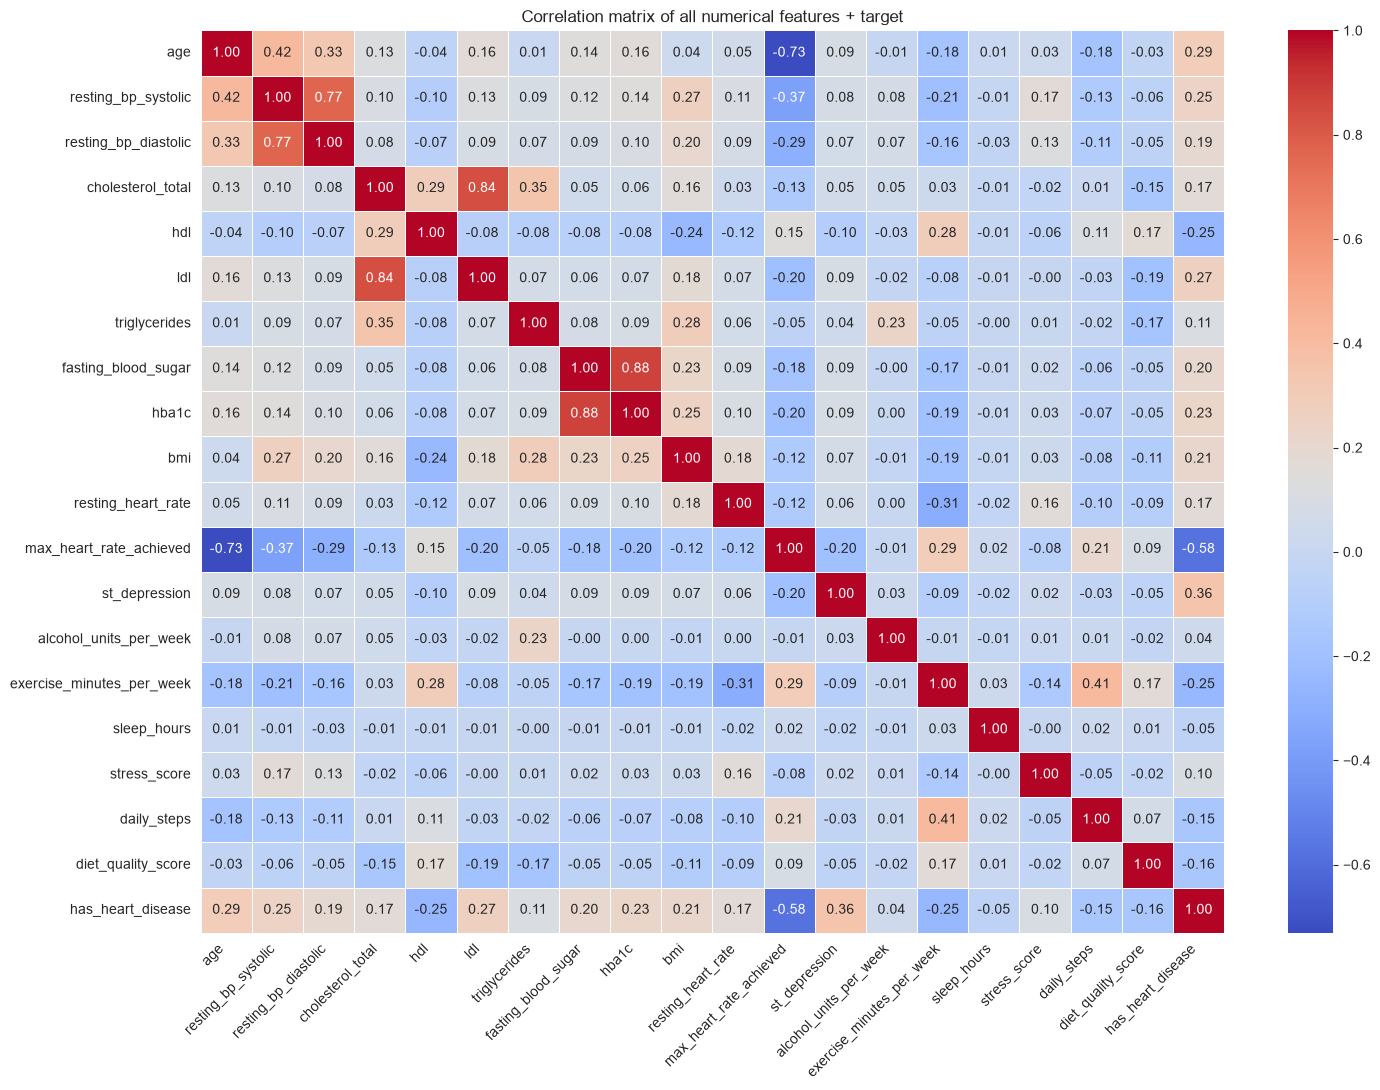

In [51]:
# ===== 5.12 Correlation matrix =====
# the last row/column shows how each feature relates to heart disease
corr = df[numerical_cols + ["has_heart_disease"]].corr()

plt.figure(figsize=(15, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            cbar=True, linewidths=0.5)
plt.title("Correlation matrix of all numerical features + target")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Reading the matrix

- **Last row / last column (correlation with heart disease):** the strongest values are
  `max_heart_rate_achieved` (r = -0.58), `st_depression` (r = +0.36), `age` (r = +0.29),
  `ldl` (r = +0.27), `hdl` (r = -0.25) and `resting_bp_systolic` (r = +0.25). This matches
  the summary table in 5.11.
- **Feature vs feature:** `age` and `max_heart_rate_achieved` are strongly negatively
  correlated (r = -0.73): older patients reach a lower maximum heart rate. This is the
  relationship we use later in Part 8 for the regression task.
- **Feature vs feature:** `resting_bp_systolic` and `resting_bp_diastolic` are strongly
  correlated (r ≈ 0.5), which is expected since they are measured together. `hdl` is
  negatively correlated with `triglycerides`, and the cholesterol-related features
  (`cholesterol_total`, `ldl`, `hdl`, `triglycerides`) form a small cluster, meaning they
  partly overlap as predictors.

### Part 5: Key observations

- **Strongest relationships with heart disease:**
  - `max_heart_rate_achieved` (**r = -0.58**, negative): patients with disease reach a much
    lower maximum heart rate during exercise. The strongest signal in the whole dataset.
  - `st_depression` (**r = +0.36**): higher ST depression goes with more disease.
  - `age` (**r = +0.29**), `ldl` (**r = +0.27**), `hdl` (**r = -0.25**), systolic BP (**r = +0.25**).
- **Weakest relationships:** `alcohol_units_per_week` (r ≈ 0.04), `age` vs `bmi` (r ≈ 0.04) and
  `hdl` vs `ldl` (r ≈ -0.08), so these pairs are effectively independent.
- **Clear categorical patterns:** Typical Angina (47.9% disease rate), current smokers (46.4%) and
  family history (35.6%) all raise the disease rate noticeably.
- The variables that separate the two groups best (max_heart_rate_achieved, st_depression, age,
  cholesterol fractions, BP) are the ones we would feed into a future predictive model.

# Part 6: Data Quality Assessment

Good statistics start with clean data. In this part we check the dataset for three common
problems and discuss what we would do if we found any:

1. **Missing values:** cells that are empty (NaN). They force us to decide: drop the row,
   or fill the gap (impute) with a reasonable number such as the mean/median/mode.
2. **Duplicate rows:** the same patient appearing more than once. Duplicates would make that
   patient count double in every calculation, so we would drop them.
3. **Unusual / impossible values:** numbers that cannot be real (e.g. a negative BMI, or a
   blood pressure of 0). They are usually data-entry errors and must be fixed or removed.

> A useful distinction: the **outliers** we found in Part 3 (IQR rule) are *statistically*
> unusual but can still be real patients (e.g. high blood pressure, obesity). The **impossible
> values** checked here are *physically impossible* and are almost certainly errors.

### 6.1 Missing values

In [52]:
# CHECK 1: MISSING VALUES

# df.isna() marks empty cells, .sum() counts them per column
missing_values = df.isna().sum()

print("Missing values per column:")
print(missing_values)
print()
print("Total missing values in the whole dataset:", missing_values.sum())

Missing values per column:
patient_id                   0
age                          0
sex                          0
resting_bp_systolic          0
resting_bp_diastolic         0
cholesterol_total            0
hdl                          0
ldl                          0
triglycerides                0
fasting_blood_sugar          0
hba1c                        0
bmi                          0
resting_heart_rate           0
max_heart_rate_achieved      0
chest_pain_type              0
exercise_induced_angina      0
st_depression                0
family_history               0
smoker_status                0
alcohol_units_per_week       0
exercise_minutes_per_week    0
sleep_hours                  0
stress_score                 0
wearable_owner               0
daily_steps                  0
diet_quality_score           0
has_heart_disease            0
hd_label                     0
dtype: int64

Total missing values in the whole dataset: 0


### 6.2 Duplicate rows

In [53]:
# CHECK 2: DUPLICATE ROWS

# rows that repeat an earlier row, counted with .sum()
dup_count = df.duplicated().sum()
print("Number of duplicate rows:", dup_count)

Number of duplicate rows: 0


### 6.3 Unusual / impossible values

In [54]:
# CHECK 3: MINIMUM AND MAXIMUM OF EVERY NUMERICAL COLUMN

# If the minimum or maximum is impossible (e.g. BMI of -5), we have a data error.
print("Smallest and largest value of each numerical column:")
print("  (units: age=years, BP=mm Hg, cholesterol/sugar=mg/dL, bmi=kg/m^2)")
print()
for col in numerical_cols:
    print(f"{col:30s} min = {df[col].min():8.2f}   max = {df[col].max():8.2f}")

# also make sure no column has negative values
negative_cols = [col for col in numerical_cols if (df[col] < 0).any()]
print()
print("Columns that contain negative values:", negative_cols if negative_cols else "none")

Smallest and largest value of each numerical column:
  (units: age=years, BP=mm Hg, cholesterol/sugar=mg/dL, bmi=kg/m^2)

age                            min =    18.00   max =    90.00
resting_bp_systolic            min =    85.00   max =   181.00
resting_bp_diastolic           min =    50.00   max =   126.00
cholesterol_total              min =    90.00   max =   314.00
hdl                            min =    18.00   max =   110.00
ldl                            min =    35.00   max =   207.00
triglycerides                  min =    35.00   max =   390.00
fasting_blood_sugar            min =    60.00   max =   204.00
hba1c                          min =     4.00   max =     8.60
bmi                            min =    15.00   max =    43.30
resting_heart_rate             min =    48.00   max =   111.00
max_heart_rate_achieved        min =    93.00   max =   210.00
st_depression                  min =     0.00   max =     6.50
alcohol_units_per_week         min =     0.00   max =    45

In [55]:
# CHECK 4: SENSIBLE-RANGE BOUNDS CHECK

# a clinically sensible range for each column; anything outside is suspicious
sensible_ranges = {
    "age":                       (0, 120),     # years
    "resting_bp_systolic":       (50, 260),    # mm Hg
    "resting_bp_diastolic":      (30, 200),    # mm Hg
    "cholesterol_total":         (50, 700),    # mg/dL
    "hdl":                       (5, 200),     # mg/dL
    "ldl":                       (5, 500),     # mg/dL
    "triglycerides":             (10, 1000),   # mg/dL
    "fasting_blood_sugar":       (30, 500),    # mg/dL
    "hba1c":                     (2, 20),      # %
    "bmi":                       (10, 70),     # kg/m^2
    "resting_heart_rate":        (20, 220),    # beats per minute
    "max_heart_rate_achieved":   (30, 260),    # bpm
    "st_depression":             (0, 10),      # mm
    "alcohol_units_per_week":    (0, 200),
    "exercise_minutes_per_week": (0, 3000),
    "sleep_hours":               (0, 24),
    "stress_score":              (0, 100),
    "daily_steps":               (0, 100000),
    "diet_quality_score":        (0, 100),
}

print("Checking every numerical column against its sensible range...")
print()
any_problem = False
for col, (low, high) in sensible_ranges.items():
    bad = df[(df[col] < low) | (df[col] > high)]
    if len(bad) > 0:
        any_problem = True
        print(f"PROBLEM in {col}: {len(bad)} rows outside [{low}, {high}]")

if not any_problem:
    print("No impossible values found - every column is within its sensible range.")

Checking every numerical column against its sensible range...

No impossible values found - every column is within its sensible range.


In [56]:
# CHECK 5: CATEGORICAL COLUMNS - ANY UNEXPECTED CATEGORIES?

# a typo in a category (e.g. "mal") would show up here
expected_categories = {
    "sex":             ["Male", "Female"],
    "chest_pain_type": ["Asymptomatic", "Non-Anginal Pain", "Atypical Angina", "Typical Angina"],
    "smoker_status":   ["Never", "Former", "Current"],
}

for col, allowed in expected_categories.items():
    found = set(df[col].unique())
    unexpected = found - set(allowed)
    if unexpected:
        print(f"{col}: UNEXPECTED categories -> {unexpected}")
    else:
        print(f"{col}: only the expected categories were found")

sex: only the expected categories were found
chest_pain_type: only the expected categories were found
smoker_status: only the expected categories were found


### 6.4 Discussion: what we found and how we would handle problems

**Result: the dataset is completely clean.**
- **Missing values:** 0 in every column. Nothing to impute.
- **Duplicate rows:** 0. No patient is counted twice.
- **Impossible values:** none. Every numerical column sits inside a clinically plausible range,
  there are no negative values, and every categorical column contains only the expected categories.

**Why does this matter (and how would we handle a problem if there was one)?**
- **Missing values** reduce our sample size and can bias the averages. Options are to **drop**
  the affected rows (safe when only a few rows are affected) or **impute** (fill with the
  median, best for skewed data, mean, or mode). Since we have 9000 rows and none are missing,
  this step is unnecessary here.
- **Duplicate rows** would make one patient count twice in every table and plot, which
  over-weights that patient. They are simply **dropped** (`df.drop_duplicates()`).
- **Impossible values** (e.g. BP = 0, negative BMI) are usually entry errors. They can be
  corrected, replaced with the median, or the row removed. Otherwise they can drag the mean
  and correlations in the wrong direction.

**Important note about the Part 3 outliers:** the IQR outliers we identified earlier (e.g. high
ST-depression, obesity, very heavy drinking) are *extreme but real* patients, not data errors.
We should **keep** them in the analysis because they are exactly the high-risk group we care
about.

### Part 6: Conclusion
No data cleaning is needed before modelling: the dataset is ready to use as it is.

# Part 7: Key Insights

We have now described the dataset, measured its centre and spread, looked at the shape of every
distribution, analysed the categorical variables, explored how the features relate to each other
and to heart disease, and confirmed the data quality. In this final part we bring together the
most important findings.

First, a quick recap of the numbers that drive the conclusions.

In [57]:
# key numbers for the final summary

# 1) strongest numeric predictors (by |r|)
top = df[numerical_cols].corrwith(df["has_heart_disease"]).sort_values(key=abs, ascending=False).head(8)
top_predictors = pd.DataFrame({
    "Feature": top.index,
    "r (correlation with disease)": top.values.round(3),
}).reset_index(drop=True)

print("Strongest numeric predictors of heart disease:")
print(top_predictors.to_string(index=False))
print()

# 2) disease rate (%) within key categorical groups
rate_rows = []
for col in ["chest_pain_type", "smoker_status", "sex", "family_history"]:
    rates = (df.groupby(col)["has_heart_disease"].mean() * 100)
    for group, r in rates.items():
        rate_rows.append([col, group, round(r, 1)])

rate_table = pd.DataFrame(rate_rows, columns=["Variable", "Group", "Disease rate (%)"])
print("Disease rate inside each categorical group:")
print(rate_table.to_string(index=False))

Strongest numeric predictors of heart disease:
                  Feature  r (correlation with disease)
  max_heart_rate_achieved                        -0.581
            st_depression                         0.357
                      age                         0.291
                      ldl                         0.267
                      hdl                        -0.252
      resting_bp_systolic                         0.249
exercise_minutes_per_week                        -0.248
                    hba1c                         0.226

Disease rate inside each categorical group:
       Variable            Group  Disease rate (%)
chest_pain_type     Asymptomatic              25.4
chest_pain_type  Atypical Angina              35.5
chest_pain_type Non-Anginal Pain              27.8
chest_pain_type   Typical Angina              47.9
  smoker_status          Current              46.4
  smoker_status           Former              30.3
  smoker_status            Never              2

### 7.1 The typical patient profile of heart disease

Comparing patients **with** disease against those **without**, the disease group is clearly
different on almost every clinical measurement:

| Feature | No disease | With disease | Direction |
|---|---|---|---|
| Age (years) | 51.5 | 59.7 | older |
| Systolic BP (mm Hg) | 125.6 | 133.1 | higher |
| Diastolic BP (mm Hg) | 79.4 | 84.0 | higher |
| LDL (bad cholesterol, mg/dL) | 98.5 | 114.4 | higher |
| HDL (good cholesterol, mg/dL) | 57.3 | 50.5 | lower |
| BMI (kg/m²) | 24.7 | 26.7 | higher |
| Fasting blood sugar (mg/dL) | 116.4 | 126.5 | higher |

So the risk profile is coherent: **older age, worse cholesterol balance, higher blood pressure,
higher weight, and higher blood sugar** all go together with heart disease. These are exactly the
risk factors doctors look for in real life.

### 7.2 The strongest single signals in the data

1. **`max_heart_rate_achieved` (r = -0.58):** by far the most informative feature. Patients with
   disease reach a much lower maximum heart rate during exercise, which makes sense: heart disease
   limits physical capacity.
2. **`st_depression` (r = +0.36):** a classic ECG sign of heart disease; it is also the most
   right-skewed feature in the dataset.
3. **Age (r = +0.29)**, **LDL (r = +0.27)**, **HDL (r = -0.25)**, **systolic BP (r = +0.25)**.

### 7.3 Categorical and lifestyle insights

- **Chest pain type** is informative: **Typical Angina → 47.9%** disease rate vs **Asymptomatic →
  25.4%**. (Remember from Part 4 that Asymptomatic is still the most common type overall.)
- **Smoking matters a lot:** **Current smokers → 46.4%** disease rate vs **Never → 25.2%**.
- **Family history → 35.6%** vs **28.3%** without.
- **Sex:** males **35.4%** vs females **24.7%**.
- **Alcohol is a weak factor** (r = 0.04), far less important than smoking in this dataset.

### 7.4 Variables most useful for future predictive modeling

**Strong candidates (keep):** `max_heart_rate_achieved`, `st_depression`, `age`, `ldl`, `hdl`,
`resting_bp_systolic`, `exercise_minutes_per_week`, `hba1c`, `bmi`, `fasting_blood_sugar`, and the
categorical variables `chest_pain_type`, `smoker_status`, `family_history`, `sex`.

**Weakest candidates (least useful):** `alcohol_units_per_week` (r ≈ 0.04), `sleep_hours`
(r ≈ -0.05), `stress_score` (r ≈ 0.10) and `triglycerides` (r ≈ 0.11).

**One modelling warning:** the target is **imbalanced**: only 30.3% of patients have heart
disease. A model that always predicts "no disease" would be ~70% "accurate" while learning
nothing, so the future model must be evaluated with care (e.g. precision/recall or balanced
metrics), not plain accuracy.

### 7.5 Final conclusion

The dataset tells one coherent clinical story: heart disease is associated with older age, a
worse cholesterol profile, higher blood pressure, higher BMI, higher blood sugar, lower exercise
capacity, smoking, and certain chest-pain types. The data is completely clean (no missing values,
no duplicates, no impossible values), so these patterns are trustworthy. This exploratory analysis
gives an excellent starting point for the predictive modelling work carried out in Part 8.


# Part 8: Predictive Modeling - Heart Disease Risk (2026)

Course: Statistics for Data Science (CSE303)
Stage: predictive modeling (extends the exploratory analysis from Part 1)

In Part 1 we explored the Heart Disease Risk 2026 dataset (9000 patients, 27 columns) with descriptive
statistics, distribution plots, categorical analysis, relationships between variables and a full
data-quality check. The data turned out to be clean (no missing values, no duplicates, no impossible
values) and we found clear signals: low max heart rate, high ST depression, older age, high LDL, low
HDL and high blood pressure all go together with heart disease.

This part (Part 8) of the notebook carries the modelling work. We build the models
required by the assignment:

1. Linear Regression on a numerical feature (a regression task)
2. Logistic Regression on the target variable (a classification task)

We then compare them with a few additional models (k-Nearest Neighbors, Decision Tree, Random Forest,
Naive Bayes) to see whether a different algorithm does better. All models are evaluated on a testing
set that the model has never seen during training.

## Setup: importing the libraries

Same libraries as Part 1 (`pandas`, `numpy`, `matplotlib`, `seaborn`) plus **scikit-learn**, which
gives us the models, the train-test split and the evaluation metrics.

In [58]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve)

df = pd.read_csv("heart_disease_risk_2026.csv")

print(df.shape[0], "rows,", df.shape[1], "columns")

9000 rows, 27 columns


## 8.1 Quick recap of Part 1 (what we build on)

- 9000 patients, 27 columns, no missing values, no duplicates.
- Target `has_heart_disease`: 1 = disease (2727, 30.3%), 0 = no disease (69.7%). The target is
  imbalanced, which will matter when we judge the classification models.
- Strongest numeric signals (correlation with disease): `max_heart_rate_achieved` (r = -0.58),
  `st_depression` (r = +0.36), `age` (r = +0.29), `ldl` (r = +0.27), `hdl` (r = -0.25),
  `resting_bp_systolic` (r = +0.25).
- Strongest categorical signals: Typical Angina (47.9% disease rate), current smokers (46.4%),
  family history (35.6%), males (35.4% vs 24.7% for females).

We feed all of these features into the models below.

## 8.2 Preparing the data for the models

Models only accept numbers, so we convert the text categories:

- `sex`, `chest_pain_type` and `smoker_status` are words, so we turn them into **dummy (0/1) columns**.
- The True/False columns (`exercise_induced_angina`, `family_history`, `wearable_owner`) become 0/1.
- `patient_id` is just an ID number, not a real feature, so we leave it out.

For the dummy columns we use `drop_first = True` so that, for example, only one column `sex_Male`
is created (1 for Male, 0 for Female). One 0/1 column is enough to store two groups; adding a second
column would just repeat the same information.

In [59]:
# same 19 numerical features as in Part 1
numerical_cols = [
    "age", "resting_bp_systolic", "resting_bp_diastolic",
    "cholesterol_total", "hdl", "ldl", "triglycerides",
    "fasting_blood_sugar", "hba1c", "bmi",
    "resting_heart_rate", "max_heart_rate_achieved", "st_depression",
    "alcohol_units_per_week", "exercise_minutes_per_week", "sleep_hours",
    "stress_score", "daily_steps", "diet_quality_score",
]

categorical_cols = [
    "sex", "chest_pain_type", "smoker_status",
    "exercise_induced_angina", "family_history", "wearable_owner",
]

# word categories -> 0/1 dummy columns (one less column than categories)
df_cat = pd.get_dummies(df[categorical_cols], drop_first=True, dtype=int)

# join the numbers and the dummies into one feature table
X = pd.concat([df[numerical_cols], df_cat], axis=1)

y = df["has_heart_disease"]

print("Feature matrix shape (rows, columns):", X.shape)
print("Target: 0 = no disease (count", (y == 0).sum(), "), 1 = disease (count", (y == 1).sum(), ")")

Feature matrix shape (rows, columns): (9000, 28)
Target: 0 = no disease (count 6273 ), 1 = disease (count 2727 )


Now we split the data into a **training set** (80%) and a **testing set** (20%). The model is fitted
(learns) on the training set only, then predicts on the testing set which it has never seen. Comparing
those predictions with the real values shows how well the model would work on new patients.

We fix `random_state = 42` so the split is the same every time. For the classification task we use
`stratify = y`: this keeps the same percentage of disease patients (30.3%) in both sets, which is
important because the target is imbalanced.

In [60]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape[0], "| Testing set size:", X_test.shape[0])
print("Positive rate in training set: %.2f%%" % (y_train.mean() * 100))
print("Positive rate in testing  set: %.2f%%" % (y_test.mean() * 100))

Training set size: 7200 | Testing set size: 1800
Positive rate in training set: 30.31%
Positive rate in testing  set: 30.28%


## 8.3 Linear Regression (regression task)

### Choosing the target and the feature

The assignment asks for a regression task on an appropriate numerical feature. We predict:

- **Target:** `max_heart_rate_achieved` (highest heart rate during exercise, in bpm). It is a
  continuous numerical variable, exactly what regression should predict.
- **Feature:** `age` (in years).

There is a well-known medical rule of thumb that maximum heart rate falls with age (roughly 220 minus
age). Part 1 already showed a strong correlation (r = -0.73) between `age` and `max_heart_rate_achieved`,
so a straight line should fit well. We fit

> max_heart_rate = b0 + b1 * age

on the training set, then evaluate it on the testing set with **MSE** and **RMSE** (and R-squared as
extra context).

In [61]:
age_train, age_test, hr_train, hr_test = train_test_split(
    df[["age"]], df["max_heart_rate_achieved"], test_size=0.2, random_state=42
)
print("Training size:", len(age_train), "| Testing size:", len(age_test))

# ---- method 1: our own manual linear regression (normal equation) ----
def linear_regression_manual(X, y):
    """
    Manual linear regression using normal equation:
    beta = (X^T X)^-1 * X^T y
    """
    # Add intercept column (column of ones)
    X = np.column_stack([np.ones(len(X)), X])

    # Step 1: Compute X^T * X
    XtX = X.T @ X

    # Step 2: Compute inverse of XtX (using np.linalg.inv)
    XtX_inv = np.linalg.inv(XtX)

    # Step 3: Compute X^T * y
    Xt_y = X.T @ y

    # Step 4: Compute beta = (XtX_inv) @ (Xt_y)
    beta = XtX_inv @ Xt_y

    return beta


def predict_linear(X, beta):
    """Manual prediction: y = beta0 + beta1*x"""
    X = np.column_stack([np.ones(len(X)), X])
    return X @ beta


# Train manually with the real training data
beta = linear_regression_manual(age_train.values, hr_train.values)

# Predict manually on the testing data
hr_pred_manual = predict_linear(age_test.values, beta)

# Evaluate the manual model
mse_manual = mean_squared_error(hr_test, hr_pred_manual)
rmse_manual = np.sqrt(mse_manual)
r2_manual = r2_score(hr_test, hr_pred_manual)

# R-squared written out by hand, to show we understand the formula:
#   R2 = 1 - (SSR / SST)  where SSR = error left over, SST = total variation
sst = np.sum((hr_test - hr_test.mean()) ** 2)   # total variation in the real values
ssr = np.sum((hr_test - hr_pred_manual) ** 2)   # error the model still makes
r2_by_hand = 1 - (ssr / sst)                    # fraction of variation explained

print("Manual linear regression (Normal Equation with np.linalg.inv):")
print("  Fitted line: max_heart_rate = %.2f + (%.3f) * age" % (beta[0], beta[1]))
print("  Testing set: MSE = %.2f  |  RMSE = %.2f  |  R-squared = %.3f" % (mse_manual, rmse_manual, r2_manual))
print("  R-squared by hand (1 - SSR/SST) = %.4f  (same as sklearn)" % r2_by_hand)
print()

# ---- method 2: the sklearn LinearRegression model ----
lin_reg = LinearRegression()
lin_reg.fit(age_train, hr_train)
hr_pred = lin_reg.predict(age_test)

mse = mean_squared_error(hr_test, hr_pred)
rmse = np.sqrt(mse)
r2 = r2_score(hr_test, hr_pred)

print("sklearn LinearRegression:")
print("  Fitted line: max_heart_rate = %.2f + (%.3f) * age" % (lin_reg.intercept_, lin_reg.coef_[0]))
print("  Testing set: MSE = %.2f  |  RMSE = %.2f  |  R-squared = %.3f" % (mse, rmse, r2))
print()

# ---- compare: both methods must agree ----
print("Comparison (manual vs sklearn):")
print("  Intercept:   %.4f  vs  %.4f" % (beta[0], lin_reg.intercept_))
print("  Slope (age): %.4f  vs  %.4f" % (beta[1], lin_reg.coef_[0]))
print("  MSE:         %.4f  vs  %.4f" % (mse_manual, mse))
print("  RMSE:        %.4f  vs  %.4f" % (rmse_manual, rmse))
print("  R-squared:   %.4f  vs  %.4f" % (r2_manual, r2))

Training size: 7200 | Testing size: 1800
Manual linear regression (Normal Equation with np.linalg.inv):
  Fitted line: max_heart_rate = 229.64 + (-1.201) * age
  Testing set: MSE = 216.43  |  RMSE = 14.71  |  R-squared = 0.524
  R-squared by hand (1 - SSR/SST) = 0.5244  (same as sklearn)

sklearn LinearRegression:
  Fitted line: max_heart_rate = 229.64 + (-1.201) * age
  Testing set: MSE = 216.43  |  RMSE = 14.71  |  R-squared = 0.524

Comparison (manual vs sklearn):
  Intercept:   229.6355  vs  229.6355
  Slope (age): -1.2006  vs  -1.2006
  MSE:         216.4283  vs  216.4283
  RMSE:        14.7115  vs  14.7115
  R-squared:   0.5244  vs  0.5244


C:\Users\nirjo\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


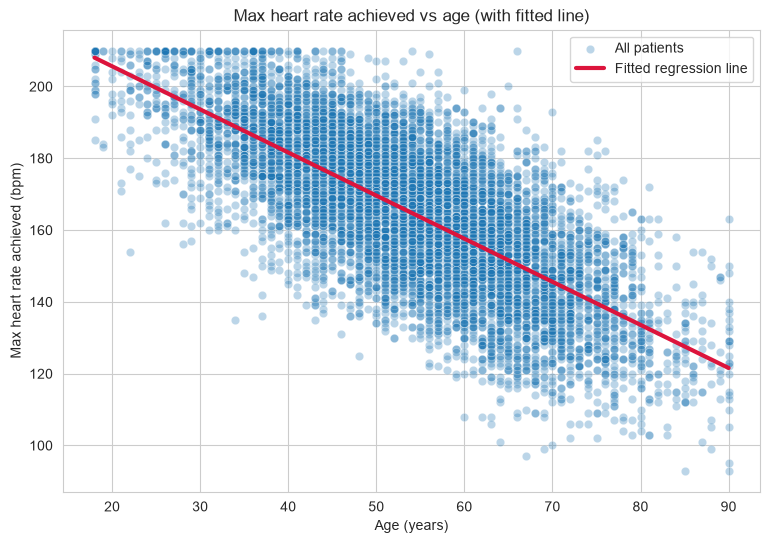

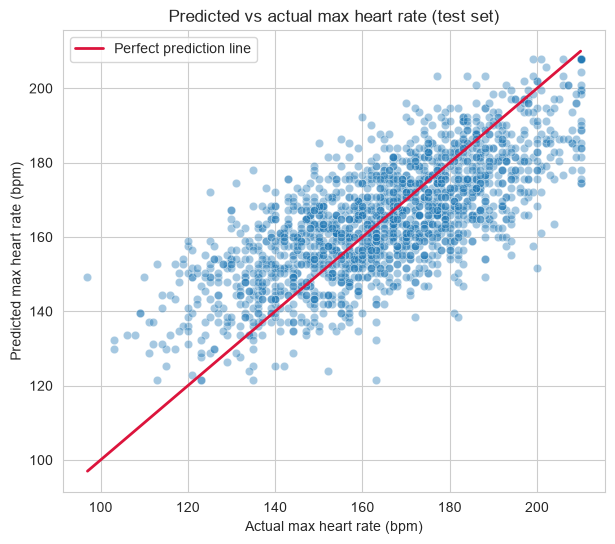

In [62]:
# Plot 1: the data with the fitted regression line
plt.figure(figsize=(9, 6))
sns.scatterplot(x=df["age"], y=df["max_heart_rate_achieved"], alpha=0.3, label="All patients")
age_line = np.linspace(df["age"].min(), df["age"].max(), 100)
hr_line = lin_reg.predict(age_line.reshape(-1, 1))
plt.plot(age_line, hr_line, color="crimson", linewidth=3, label="Fitted regression line")
plt.title("Max heart rate achieved vs age (with fitted line)")
plt.xlabel("Age (years)")
plt.ylabel("Max heart rate achieved (bpm)")
plt.legend()
plt.show()

# Plot 2: predicted vs actual on the TEST set (a good fit hugs the diagonal)
plt.figure(figsize=(7, 6))
sns.scatterplot(x=hr_test, y=hr_pred, alpha=0.4)
plt.plot([hr_test.min(), hr_test.max()], [hr_test.min(), hr_test.max()],
         color="crimson", linewidth=2, label="Perfect prediction line")
plt.title("Predicted vs actual max heart rate (test set)")
plt.xlabel("Actual max heart rate (bpm)")
plt.ylabel("Predicted max heart rate (bpm)")
plt.legend()
plt.show()

### Reading the simple linear regression results

- Fitted line: `max_heart_rate = 229.64 - 1.20 * age`. Each extra year of age lowers the predicted max
  heart rate by about **1.2 bpm** on average, which matches the medical rule of thumb.
- MSE = 216.43, RMSE = 14.71: on the testing set our predictions are off by about **14.7 bpm** on
  average. Heart rate also depends on fitness, medication and other things not in the dataset, so a
  single-feature model cannot be exact. An average error of ~15 bpm seems reasonable for that.
- R-squared = 0.52: age alone explains about **52%** of the variation in max heart rate. Strong for
  one feature, and it confirms the relationship we saw in Part 1 (r = -0.73).

### Improving the model: multiple linear regression

To try to reduce the error, we add a few more clinical features that could affect heart rate: `bmi`,
`resting_bp_systolic`, `hba1c`, `resting_heart_rate` and `sex`. Same Linear Regression technique, just
with more than one predictor. The X table we built already contains the `sex_Male` dummy column.

In [63]:
mlr_cols = ["age", "bmi", "resting_bp_systolic", "hba1c", "resting_heart_rate", "sex_Male"]
X_mlr = X[mlr_cols]

X_mlr_train, X_mlr_test, hr_train2, hr_test2 = train_test_split(
    X_mlr, df["max_heart_rate_achieved"], test_size=0.2, random_state=42
)

mlr = LinearRegression()
mlr.fit(X_mlr_train, hr_train2)
hr_pred2 = mlr.predict(X_mlr_test)

mse2 = mean_squared_error(hr_test2, hr_pred2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(hr_test2, hr_pred2)

print("Coefficients (change in max heart rate per unit of each feature):")
for col, coef in zip(mlr_cols, mlr.coef_):
    print("  %-22s %8.3f" % (col, coef))
print("Intercept: %.2f" % mlr.intercept_)
print()
print("Testing set:  MSE = %.2f  |  RMSE = %.2f  |  R-squared = %.3f" % (mse2, rmse2, r2_2))

Coefficients (change in max heart rate per unit of each feature):
  age                      -1.144
  bmi                      -0.287
  resting_bp_systolic      -0.074
  hba1c                    -1.769
  resting_heart_rate       -0.163
  sex_Male                 -2.425
Intercept: 268.09

Testing set:  MSE = 207.17  |  RMSE = 14.39  |  R-squared = 0.545


In [64]:
# ============================================================
# MULTIPLE REGRESSION DONE BY HAND - 6 FEATURES (START)
# ============================================================

# This cell builds its own data and fits its own sklearn model, so it
# works even if the cells above it were not run (needs Part 8 setup).

# the same 6 features we picked earlier
mlr_cols = ["age", "bmi", "resting_bp_systolic", "hba1c", "resting_heart_rate", "sex_Male"]

# build the feature table and split it 80% train / 20% test
X_mlr = X[mlr_cols]
X_mlr_train, X_mlr_test, hr_train2, hr_test2 = train_test_split(
    X_mlr, df["max_heart_rate_achieved"], test_size=0.2, random_state=42
)

# ---- method 1: our own manual multiple regression (normal equation) ----
# formula: beta = (X^T X)^-1 * X^T y
def normal_equation(X, y):
    X = np.column_stack([np.ones(len(X)), X])   # add a column of ones for the intercept
    XtX = X.T @ X                               # step 1: X^T X
    XtX_inv = np.linalg.inv(XtX)                # step 2: inverse of X^T X
    beta = XtX_inv @ (X.T @ y)                  # step 3: (X^T X)^-1 * X^T y
    return beta

def predict_many(X, beta):
    X = np.column_stack([np.ones(len(X)), X])   # same column of ones for predictions
    return X @ beta

# train manually on the 6 features
beta_mlr = normal_equation(X_mlr_train.values, hr_train2.values)

# predict manually on the testing set
hr_pred_manual2 = predict_many(X_mlr_test.values, beta_mlr)

# evaluate the manual model
mse_manual2 = mean_squared_error(hr_test2, hr_pred_manual2)
rmse_manual2 = np.sqrt(mse_manual2)
r2_manual2 = r2_score(hr_test2, hr_pred_manual2)

# R-squared written out by hand: R2 = 1 - (SSR / SST)
sst2 = np.sum((hr_test2 - hr_test2.mean()) ** 2)   # total variation of the real values
ssr2 = np.sum((hr_test2 - hr_pred_manual2) ** 2)   # error the model still makes
r2_by_hand2 = 1 - (ssr2 / sst2)

print("Manual multiple regression (6 features, normal equation):")
print("Intercept:", round(beta_mlr[0], 2))
for col, b in zip(mlr_cols, beta_mlr[1:]):
    print("  ", col, "=", round(b, 3))
print("Testing set: MSE =", round(mse_manual2, 2), "| RMSE =", round(rmse_manual2, 2), "| R-squared =", round(r2_manual2, 3))
print("R-squared by hand =", round(r2_by_hand2, 4))
print()

# ---- method 2: the sklearn LinearRegression model (for comparison) ----
mlr = LinearRegression()
mlr.fit(X_mlr_train, hr_train2)
hr_pred2 = mlr.predict(X_mlr_test)

mse2 = mean_squared_error(hr_test2, hr_pred2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(hr_test2, hr_pred2)

print("sklearn LinearRegression (6 features):")
print("Intercept:", round(mlr.intercept_, 2))
print("Testing set: MSE =", round(mse2, 2), "| RMSE =", round(rmse2, 2), "| R-squared =", round(r2_2, 3))
print()

# ---- compare: both methods must give the same answer ----
print("Comparison (manual vs sklearn):")
print("Intercept:", round(beta_mlr[0], 4), "vs", round(mlr.intercept_, 4))
for col, b, c in zip(mlr_cols, beta_mlr[1:], mlr.coef_):
    print("  ", col, ":", round(b, 4), "vs", round(c, 4))
print("MSE:", round(mse_manual2, 4), "vs", round(mse2, 4))
print("RMSE:", round(rmse_manual2, 4), "vs", round(rmse2, 4))
print("R-squared:", round(r2_manual2, 4), "vs", round(r2_2, 4))

# ============================================================
# MULTIPLE REGRESSION DONE BY HAND - 6 FEATURES (END)
# ============================================================

Manual multiple regression (6 features, normal equation):
Intercept: 268.09
   age = -1.144
   bmi = -0.287
   resting_bp_systolic = -0.074
   hba1c = -1.769
   resting_heart_rate = -0.163
   sex_Male = -2.425
Testing set: MSE = 207.17 | RMSE = 14.39 | R-squared = 0.545
R-squared by hand = 0.5448

sklearn LinearRegression (6 features):
Intercept: 268.09
Testing set: MSE = 207.17 | RMSE = 14.39 | R-squared = 0.545

Comparison (manual vs sklearn):
Intercept: 268.0858 vs 268.0858
   age : -1.1441 vs -1.1441
   bmi : -0.287 vs -0.287
   resting_bp_systolic : -0.0744 vs -0.0744
   hba1c : -1.7693 vs -1.7693
   resting_heart_rate : -0.1633 vs -0.1633
   sex_Male : -2.4248 vs -2.4248
MSE: 207.167 vs 207.167
RMSE: 14.3933 vs 14.3933
R-squared: 0.5448 vs 0.5448


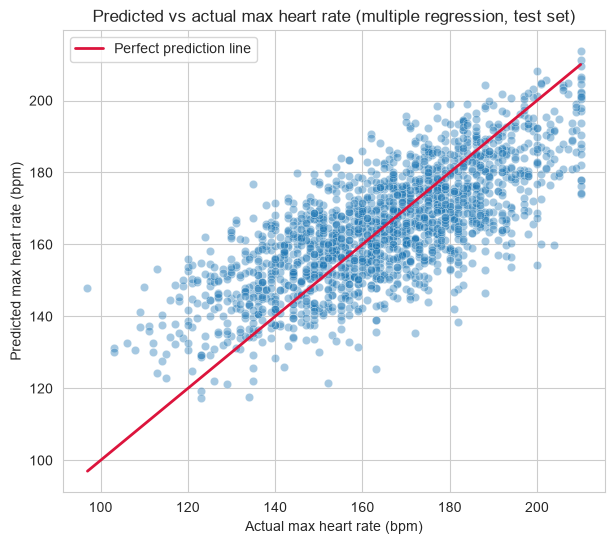

In [65]:
# Predicted vs actual for the multiple regression model
plt.figure(figsize=(7, 6))
sns.scatterplot(x=hr_test2, y=hr_pred2, alpha=0.4)
plt.plot([hr_test2.min(), hr_test2.max()], [hr_test2.min(), hr_test2.max()],
         color="crimson", linewidth=2, label="Perfect prediction line")
plt.title("Predicted vs actual max heart rate (multiple regression, test set)")
plt.xlabel("Actual max heart rate (bpm)")
plt.ylabel("Predicted max heart rate (bpm)")
plt.legend()
plt.show()

### Reading the multiple linear regression results

| Model | MSE | RMSE | R-squared |
|---|---|---|---|
| Simple (age only) | 216.43 | 14.71 | 0.524 |
| Multiple (6 features) | 207.17 | 14.39 | 0.545 |

Adding the 6 features only helped a little: RMSE went from 14.71 to 14.39 and R-squared from 0.52 to
0.55. Looking at the coefficients, **age is doing most of the work** (-1.14) and the rest are small.
So more features is not automatically better; one strong predictor was already carrying the pattern.

### What if we use all the features?

The regression above used only 6 features, but we already have a full feature table `X` with all 19
numerical features plus the dummy columns (the same set used for the classification models). There is
no reason to leave useful features out, so we now fit the regression using **everything**. This shows
whether the features we skipped earlier (smoking, exercise, ST depression, cholesterol, and so on)
carry any extra information about max heart rate.

In [66]:
# IMPORTANT: max_heart_rate_achieved is the target of this regression, so it
# must NOT be one of the features. We drop it from the feature table first.
X_hr = X.drop(columns=["max_heart_rate_achieved"])
y_hr = df["max_heart_rate_achieved"]

print("Regression feature table:", X_hr.shape[1], "features (max_heart_rate_achieved removed)")

X_all_train, X_all_test, y_hr_train, y_hr_test = train_test_split(
    X_hr, y_hr, test_size=0.2, random_state=42
)

mlr_all = LinearRegression()
mlr_all.fit(X_all_train, y_hr_train)
hr_pred_all = mlr_all.predict(X_all_test)

mse_all = mean_squared_error(y_hr_test, hr_pred_all)
rmse_all = np.sqrt(mse_all)
r2_all = r2_score(y_hr_test, hr_pred_all)

print("All-features regression on the testing set:")
print("  MSE = %.2f  |  RMSE = %.2f  |  R-squared = %.3f" % (mse_all, rmse_all, r2_all))
print()
print("Largest coefficients (features that matter most):")
coefs = pd.Series(mlr_all.coef_, index=X_hr.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8)
for name, value in top.items():
    print("  %-28s %8.3f" % (name, value))
print()
print("Smallest coefficients (features with almost no effect):")
bottom = coefs.reindex(coefs.abs().sort_values().index).head(6)
for name, value in bottom.items():
    print("  %-28s %8.3f" % (name, value))

Regression feature table: 27 features (max_heart_rate_achieved removed)
All-features regression on the testing set:
  MSE = 185.02  |  RMSE = 13.60  |  R-squared = 0.593

Largest coefficients (features that matter most):
  exercise_induced_angina        -5.397
  chest_pain_type_Typical Angina   -3.375
  smoker_status_Never             2.054
  st_depression                  -1.811
  sex_Male                       -1.505
  chest_pain_type_Atypical Angina   -1.404
  family_history                 -1.210
  smoker_status_Former            1.145

Smallest coefficients (features with almost no effect):
  daily_steps                     0.000
  resting_bp_diastolic           -0.003
  fasting_blood_sugar            -0.006
  triglycerides                  -0.009
  alcohol_units_per_week          0.021
  cholesterol_total               0.023


In [67]:
# ============================================================
# MULTIPLE REGRESSION DONE BY HAND - ALL FEATURES (START)
# ============================================================

# Same idea as the 6-feature cell, but now we use every feature.
# max_heart_rate_achieved is the TARGET, so it must NOT be a feature.
X_hr = X.drop(columns=["max_heart_rate_achieved"])
y_hr = df["max_heart_rate_achieved"]
print("Feature table:", X_hr.shape[1], "features (max_heart_rate_achieved removed)")

X_all_train, X_all_test, y_hr_train, y_hr_test = train_test_split(
    X_hr, y_hr, test_size=0.2, random_state=42
)

# the True/False columns stay as True/False after get_dummies, so we
# convert everything to float first (the matrix inverse needs numbers)
X_all_train_num = X_all_train.astype(float).values
X_all_test_num = X_all_test.astype(float).values

# ---- method 1: our own manual multiple regression (normal equation) ----
# formula: beta = (X^T X)^-1 * X^T y
def normal_equation(X, y):
    X = np.column_stack([np.ones(len(X)), X])   # add a column of ones for the intercept
    XtX = X.T @ X                               # step 1: X^T X
    XtX_inv = np.linalg.inv(XtX)                # step 2: inverse of X^T X
    beta = XtX_inv @ (X.T @ y)                  # step 3: (X^T X)^-1 * X^T y
    return beta

def predict_many(X, beta):
    X = np.column_stack([np.ones(len(X)), X])   # same column of ones for predictions
    return X @ beta

# train manually on all the features
beta_all = normal_equation(X_all_train_num, y_hr_train.values)

# predict manually on the testing set
hr_pred_manual_all = predict_many(X_all_test_num, beta_all)

# evaluate the manual model
mse_manual_all = mean_squared_error(y_hr_test, hr_pred_manual_all)
rmse_manual_all = np.sqrt(mse_manual_all)
r2_manual_all = r2_score(y_hr_test, hr_pred_manual_all)

# R-squared written out by hand: R2 = 1 - (SSR / SST)
sst_all = np.sum((y_hr_test - y_hr_test.mean()) ** 2)   # total variation of the real values
ssr_all = np.sum((y_hr_test - hr_pred_manual_all) ** 2) # error the model still makes
r2_by_hand_all = 1 - (ssr_all / sst_all)

print("Manual multiple regression (all", X_hr.shape[1], "features, normal equation):")
print("Intercept:", round(beta_all[0], 2))
print("Testing set: MSE =", round(mse_manual_all, 2), "| RMSE =", round(rmse_manual_all, 2), "| R-squared =", round(r2_manual_all, 3))
print("R-squared by hand =", round(r2_by_hand_all, 4))
print()

# ---- method 2: the sklearn LinearRegression model (for comparison) ----
mlr_all = LinearRegression()
mlr_all.fit(X_all_train, y_hr_train)
hr_pred_all = mlr_all.predict(X_all_test)

mse_all = mean_squared_error(y_hr_test, hr_pred_all)
rmse_all = np.sqrt(mse_all)
r2_all = r2_score(y_hr_test, hr_pred_all)

print("sklearn LinearRegression (all", X_hr.shape[1], "features):")
print("Intercept:", round(mlr_all.intercept_, 2))
print("Testing set: MSE =", round(mse_all, 2), "| RMSE =", round(rmse_all, 2), "| R-squared =", round(r2_all, 3))
print()

# ---- compare: both methods must give the same answer ----
print("Comparison (manual vs sklearn):")
print("Intercept:", round(beta_all[0], 4), "vs", round(mlr_all.intercept_, 4))
print("MSE:", round(mse_manual_all, 4), "vs", round(mse_all, 4))
print("RMSE:", round(rmse_manual_all, 4), "vs", round(rmse_all, 4))
print("R-squared:", round(r2_manual_all, 4), "vs", round(r2_all, 4))
print("Max difference in any coefficient:", "%.2e" % np.max(np.abs(beta_all[1:] - mlr_all.coef_)))

# ============================================================
# MULTIPLE REGRESSION DONE BY HAND - ALL FEATURES (END)
# ============================================================

Feature table: 27 features (max_heart_rate_achieved removed)
Manual multiple regression (all 27 features, normal equation):
Intercept: 234.05
Testing set: MSE = 185.02 | RMSE = 13.6 | R-squared = 0.593
R-squared by hand = 0.5935

sklearn LinearRegression (all 27 features):
Intercept: 234.05
Testing set: MSE = 185.02 | RMSE = 13.6 | R-squared = 0.593

Comparison (manual vs sklearn):
Intercept: 234.0485 vs 234.0485
MSE: 185.0229 vs 185.0229
RMSE: 13.6023 vs 13.6023
R-squared: 0.5935 vs 0.5935
Max difference in any coefficient: 1.54e-11


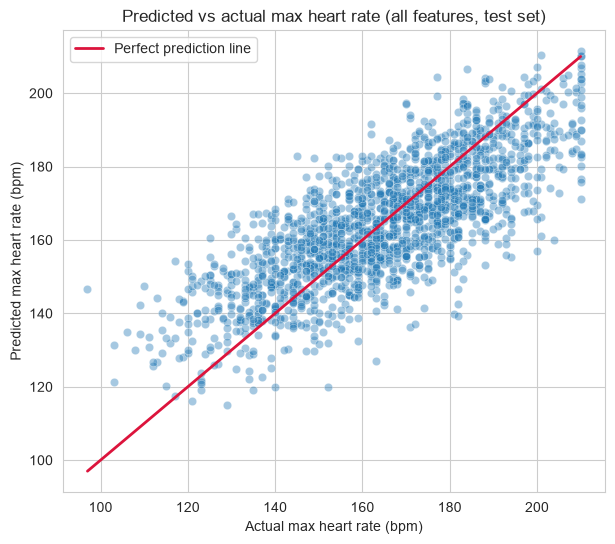

In [68]:
# Predicted vs actual for the all-features model
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_hr_test, y=hr_pred_all, alpha=0.4)
plt.plot([y_hr_test.min(), y_hr_test.max()], [y_hr_test.min(), y_hr_test.max()],
         color="crimson", linewidth=2, label="Perfect prediction line")
plt.title("Predicted vs actual max heart rate (all features, test set)")
plt.xlabel("Actual max heart rate (bpm)")
plt.ylabel("Predicted max heart rate (bpm)")
plt.legend()
plt.show()

### Reading the all-features regression results

| Model | MSE | RMSE | R-squared |
|---|---|---|---|
| Simple (age only) | 216.43 | 14.71 | 0.524 |
| Multiple (6 features) | 207.17 | 14.39 | 0.545 |
| Multiple (all features) | 185.02 | 13.60 | 0.594 |

Using all the features **did** help: RMSE fell from 14.39 to 13.60 and R-squared rose from 0.55 to
0.59. So the features we skipped in the 6-feature model were not useless.

Looking at the largest coefficients, the features that carry the most information are:

- `exercise_induced_angina` (-5.40): patients who get chest pain during exercise reach a clearly lower
  max heart rate. Makes sense: the pain stops them from pushing as hard.
- `chest_pain_type_Typical Angina` (-3.38): typical angina is also linked to a lower max heart rate.
- `smoker_status_Never` (+2.05): never-smokers reach a somewhat higher max heart rate than the baseline.
- `st_depression` (-1.81), `sex_Male` (-1.51) and `age` (-1.08): more ST depression, being male and
  older age all lower max heart rate.

The features with coefficients very close to zero (daily steps, triglycerides, fasting blood sugar,
alcohol, cholesterol, resting blood pressure) contribute almost nothing once the other features are in
the model. So the extra features from the earlier question (exercise, ST depression, smoking, chest
pain) turn out to matter, while alcohol and step count barely matter for max heart rate.

## 8.4 Logistic Regression (classification task)

### Choosing the target and the features

The assignment asks for a classification task. We predict:

- **Target:** `has_heart_disease` (1 = disease, 0 = no disease). A binary categorical target, exactly
  what logistic regression is designed for.
- **Features:** all the numerical features and the encoded categorical columns together. Logistic
  regression combines them into a single **probability** between 0 and 1 for each patient.

Part 1 showed that several features separate the two groups clearly (low max heart rate, high ST
depression, older age, worse cholesterol, higher blood pressure), so a logistic model should work well.

Because the target is imbalanced (only 30.3% have disease), plain accuracy can be misleading: a model
that always predicts "no disease" would already be ~70% correct. So besides accuracy we report the
**F1 score**, which balances precision and recall and is the better measure here. We also show the
confusion matrix and the ROC-AUC.

In [69]:
# logistic regression and kNN are sensitive to feature scale, so we
# standardise everything (mean 0, std 1) before fitting.
scaler = StandardScaler()
scaler.fit(X_train)                   # learn the scaling from the TRAINING set only
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)  # apply the same scaling to the TEST set

print("Scaling done: every feature now has mean ~0 and standard deviation ~1.")
print("Training set size:", X_train_s.shape, "| Testing set size:", X_test_s.shape)

Scaling done: every feature now has mean ~0 and standard deviation ~1.
Training set size: (7200, 28) | Testing set size: (1800, 28)


In [70]:
log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_train_s, y_train)

y_pred = log_reg.predict(X_test_s)
y_prob = log_reg.predict_proba(X_test_s)[:, 1]

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_prob)

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = actual, columns = predicted):")
print("                 predicted:  no disease    disease")
print("  actual no disease             %5d     %5d" % (cm[0, 0], cm[0, 1]))
print("  actual disease                %5d     %5d" % (cm[1, 0], cm[1, 1]))
print()
print("Accuracy  = %.4f" % acc)
print("Precision = %.4f" % prec)
print("Recall    = %.4f" % rec)
print("F1 score  = %.4f" % f1)
print("ROC-AUC   = %.4f" % auc)

Confusion matrix (rows = actual, columns = predicted):
                 predicted:  no disease    disease
  actual no disease              1186        69
  actual disease                  116       429

Accuracy  = 0.8972
Precision = 0.8614
Recall    = 0.7872
F1 score  = 0.8226
ROC-AUC   = 0.9497


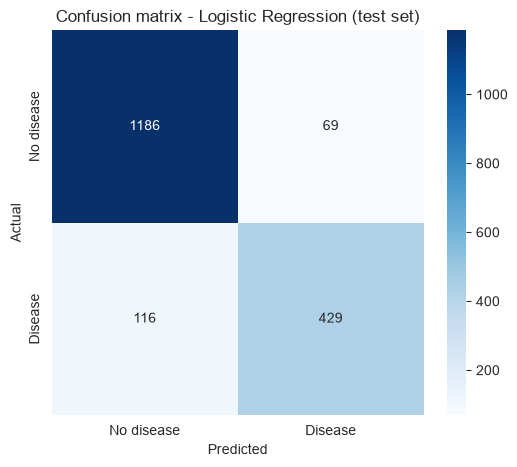

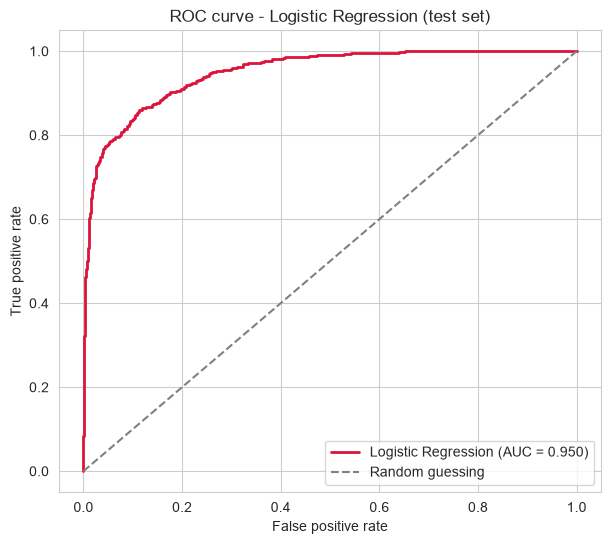

In [71]:
# confusion matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.title("Confusion matrix - Logistic Regression (test set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC curve (trade-off between true and false positive rate)
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="crimson", linewidth=2, label="Logistic Regression (AUC = %.3f)" % auc)
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing")
plt.title("ROC curve - Logistic Regression (test set)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

### Reading the logistic regression results

- Accuracy = 0.897 (about 90% of test patients were classified correctly). This looks high, but
  remember the target is imbalanced: a naive model that always says "no disease" would already reach
  ~70% accuracy. Accuracy alone is not enough.
- F1 score = 0.823 is the better measure here. It balances:
  - Precision = 0.861: when the model says "disease", it is correct about 86% of the time.
  - Recall = 0.787: the model catches about 79% of the patients who actually have disease.
- Confusion matrix: of the 1800 test patients, the model found 429 of the 545 real disease patients
  (116 missed, false negatives) and wrongly flagged only 69 healthy patients (false positives). In
  medicine, missing a disease patient (a false negative) is the more dangerous error, so the fairly
  high recall is reassuring.
- ROC-AUC = 0.950: the model ranks a random disease patient higher than a random healthy patient about
  95% of the time. The two groups are clearly well separated.

This lines up with what we saw in Part 1: the features separate the two groups very well.

## 8.5 Additional Models (optional section)

To explore further, we try four more classification models and compare them with Logistic Regression.
The models:

- **k-Nearest Neighbors (kNN):** classifies a patient by looking at the 5 closest training patients.
- **Decision Tree:** splits patients with simple if-then rules (we limit depth to 5 to avoid overfitting).
- **Random Forest:** builds many decision trees and averages their votes; usually more accurate.
- **Naive Bayes:** a simple probabilistic model using Bayes rule (assumes features are independent).

All models get the same scaled training and testing sets, so the comparison is fair. We compare
accuracy, precision, recall and F1 score.

In [72]:
extra_models = {
    "kNN":           KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Naive Bayes":   GaussianNB(),
}

rows = []
for name, model in extra_models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    rows.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
    ])

# logistic regression row added for comparison
rows.append(["Logistic Regression", acc, prec, rec, f1])

comparison = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1 score"])
comparison = comparison.round(4)
comparison

,Model,Accuracy,Precision,Recall,F1 score
0,kNN,0.8550,0.8604,0.6220,0.7220
1,Decision Tree,0.8544,0.8004,0.6917,0.7421
2,Random Forest,0.8806,0.8526,0.7321,0.7878
3,Naive Bayes,0.8700,0.7686,0.8165,0.7918
4,Logistic Regression,0.8972,0.8614,0.7872,0.8226


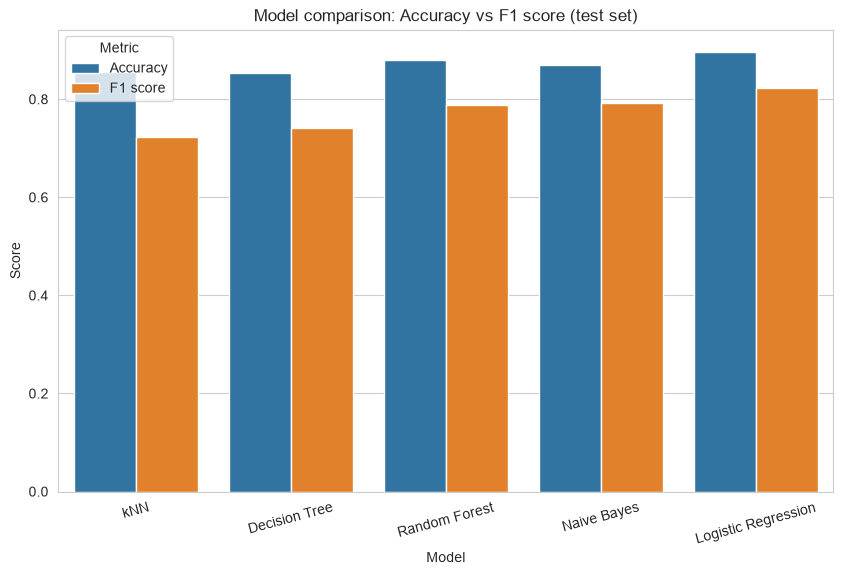

In [73]:
# bar chart comparing Accuracy and F1 score across all five models
comparison_plot = comparison.melt(id_vars="Model", value_vars=["Accuracy", "F1 score"],
                                  var_name="Metric", value_name="Value")
plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_plot, x="Model", y="Value", hue="Metric")
plt.title("Model comparison: Accuracy vs F1 score (test set)")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(title="Metric")
plt.show()

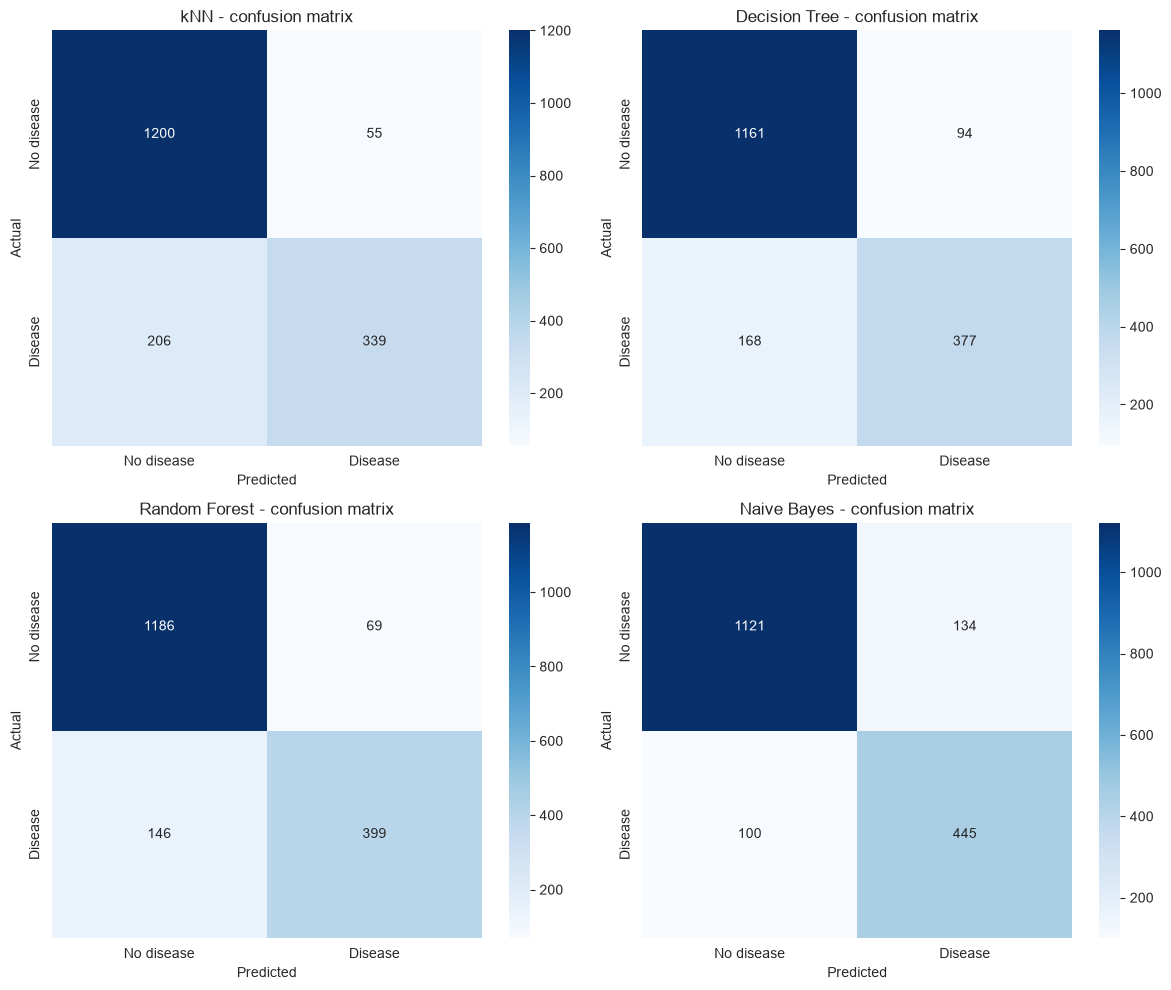

In [74]:
# confusion matrices of the four additional models, side by side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, model) in zip(axes.flat, extra_models.items()):
    pred = model.predict(X_test_s)
    cm_m = confusion_matrix(y_test, pred)
    sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No disease", "Disease"],
                yticklabels=["No disease", "Disease"])
    ax.set_title("%s - confusion matrix" % name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Reading the additional model results

| Model | Accuracy | Precision | Recall | F1 score |
|---|---|---|---|---|
| Logistic Regression | 0.897 | 0.861 | 0.787 | 0.823 |
| Random Forest | 0.881 | 0.853 | 0.732 | 0.788 |
| Naive Bayes | 0.870 | 0.769 | 0.817 | 0.792 |
| kNN | 0.855 | 0.860 | 0.622 | 0.722 |
| Decision Tree | 0.854 | 0.800 | 0.692 | 0.742 |

- Logistic Regression is the best overall on F1 (0.823) and accuracy (0.897). This makes sense: the
  data is "linear friendly" (the features separate the groups smoothly, as the AUC of 0.95 showed), so
  the simple linear model beats the more complex ones.
- Random Forest comes second (F1 0.788). It is more flexible, but here the extra flexibility does not
  help much and trees can overfit the training noise.
- Naive Bayes has the highest recall (0.817): it is aggressive at calling disease, so it misses fewer
  real patients, but at the cost of lower precision (0.769), meaning more healthy patients are wrongly
  flagged.
- kNN and the Decision Tree are the weakest. kNN suffers because the "no disease" group dominates its
  nearest neighbours, and a depth-5 tree is too simple for this data.

## 8.6 Results and Discussion

### What the results indicate

The models agree with the Part 1 findings: heart disease in this dataset is very
predictable. Logistic regression reaches ROC-AUC = 0.95 and F1 = 0.82, which is strong for a healthcare
classification task. The regression model also behaved as we would expect: age explains about 52% of
the variation in max heart rate, and the fitted slope (about -1.2 bpm per year) matches the medical
rule of thumb.

### Is the performance good or poor, and why

The performance is good, mainly because the dataset is clean and the features are informative:

- No missing values, no duplicates and no impossible values (Part 1), so the models were never
  disturbed by dirty input.
- The strongest predictors (`max_heart_rate_achieved`, `st_depression`, `age`, cholesterol fractions,
  blood pressure) separate the two groups clearly, which is why the AUC is so high.
- The target imbalance (30.3% positive) did not hurt much here because the signal is strong. It still
  matters for evaluation, which is why we relied on F1 and ROC-AUC rather than accuracy alone.

### Limitations and issues

- Class imbalance: a naive model that always predicts "no disease" would already reach ~70% accuracy.
  This is why we never judged the models by accuracy alone; F1 and AUC are more reliable here.
- Synthetic data: the dataset is artificially generated (Kaggle, "Heart Disease Risk 2026"). Real
  clinical data is noisier, so these exact numbers would likely not transfer to real patients.
- The regression is approximate: it predicts max heart rate with an RMSE of about 14 bpm. Heart rate
  also depends on fitness, medication and other factors not in the dataset.
- False negatives: in medicine, missing a real heart-disease patient is the most dangerous error. Our
  logistic model still misses about 21% of disease patients (116 of 545 in the test set). A
  higher-recall model (like Naive Bayes) catches more, but at the price of more false alarms.

### How the dataset characteristics affected the results

The clean, well-separated data is the main reason all models performed well. Because the classes are
nearly linearly separable (AUC 0.95 for logistic regression), the simplest model wins; complex models
such as Random Forest or kNN never get a chance to show an advantage. If the data were noisier or more
overlapping, the tree-based models might catch up.

## 8.7 Conclusions

1. Linear Regression modelled the relationship between age and max heart rate (RMSE ~14.7 bpm,
   R-squared ~0.52 for age alone). The fitted slope agrees with the medical rule that max heart rate
   falls by about 1.2 bpm per year of age.
2. Logistic Regression classified patients into disease / no disease with accuracy 0.897, F1 0.823 and
   ROC-AUC 0.950. Given the 30.3% positive rate, these are strong and trustworthy numbers.
3. The extra models (kNN, Decision Tree, Random Forest, Naive Bayes) confirmed that Logistic
   Regression is the best choice for this dataset. None of them beat it on F1 or accuracy.
4. The modelling confirms the Part 1 clinical story: low max heart rate, high ST depression, older age,
   worse cholesterol and higher blood pressure are the features that predict heart disease.
5. The main caveat is class imbalance: always evaluate with F1 and ROC-AUC, never with accuracy alone,
   and keep in mind the dataset is synthetic.

The two mandatory models are complete, compared and discussed. This notebook is the complete
project: Part 1 (exploratory analysis) and Part 2 (predictive modelling) together.